# Predicción de la incidencia y nivel de riesgo delictivo distrital en el Perú mediante algoritmos de aprendizaje automático sobre datos multisectoriales (2024–2025)
**Curso:** Inteligencia Artificial (1INF24) – Pontificia Universidad Católica del Perú (PUCP)  
**Integrantes (Grupo 8):** Joseph Naim Jesús González, José Fabrizio Serrano Vásquez, Johann Sebastian Mateus Escobar  

**Descripción del proyecto:**  
Desarrollo de un pipeline integral de aprendizaje automático supervisado que consolida ocho fuentes oficiales del Estado peruano a nivel distrital (`UBIGEO`) y frecuencia mensual (2024–2025). El estudio aborda de manera complementaria la **predicción del volumen mensual de denuncias (`N_DELITOS`)** mediante modelos de regresión y la **clasificación del nivel de riesgo/prioridad distrital** (`Bajo`, `Medio`, `Alto`), evaluando comparativamente algoritmos basados en árboles de decisión, K-Nearest Neighbors (KNN), modelos lineales y redes perceptrón multicapa (MLP) para apoyar la asignación estratégica de recursos policiales.

## 1. Integración de Fuentes Multisectoriales (ETL 2024–2025)
Consolidación de registros delictivos, demográficos, territoriales, policiales, socioeconómicos y de infraestructura urbana a nivel distrital y mensual.

### 1.1. Denuncias Policiales (SIDPOL)
#### 1.1.1. Carga del dataset de denuncias policiales (2024–2025)
Se importan los registros históricos de denuncias policiales del SIDPOL correspondientes a los años 2024 y 2025, concatenándolos en un único DataFrame base.

In [137]:
import pandas as pd

data_denuncias_policiales_2024 = pd.read_csv('Denuncias_Policiales_2024.csv',sep=';')
data_denuncias_policiales_2025 = pd.read_csv('Denuncias_Policiales_2025.csv',sep=';')

data_denuncias_policiales = pd.concat([data_denuncias_policiales_2024,data_denuncias_policiales_2025],ignore_index=True)
data_denuncias_policiales.head()

,ANIO,MES,UBIGEO_HECHO,DPTO_HECHO_NEW,PROV_HECHO,DIST_HECHO,TIPO,SUB_TIPO,MODALIDAD,n_dist_ID_DGC
0,2024,1,10101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,ADMINISTRACION PUBLICA (DELITO),ADMINISTRACION DE JUSTICIA,FUGA DEL LUGAR DEL ACCIDENTE DE TRANSITO,1
1,2024,1,10101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,ADMINISTRACION PUBLICA (DELITO),COMETIDOS POR FUNCIONARIOS PUBLICOS,COHECHO ACTIVO GENERICO,1
2,2024,1,10101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,LIBERTAD (DELITO),VIOLACION DE DOMICILIO,VIOLACION DE DOMICILIO,1
3,2024,1,10101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,LIBERTAD (DELITO),VIOLACION DE LA LIBERTAD PERSONAL,ACOSO,1
4,2024,1,10101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,LIBERTAD (DELITO),VIOLACION DE LA LIBERTAD PERSONAL,COACCION,1


#### 1.1.2. Agregación mensual de denuncias por distrito
Se agrupan los registros delictivos por año, mes y ubicación geográfica (`UBIGEO`) para obtener el conteo total mensual de denuncias (`N_DELITOS`), estandarizando los nombres de las columnas principales.

In [138]:
df = data_denuncias_policiales.groupby(
    ['ANIO', 'MES','DPTO_HECHO_NEW','PROV_HECHO','DIST_HECHO','UBIGEO_HECHO'], as_index=False
)['n_dist_ID_DGC'].sum()

df = df.rename(columns={'n_dist_ID_DGC': 'N_DELITOS','DPTO_HECHO_NEW': 'DEPARTAMENTO','PROV_HECHO':'PROVINCIA','DIST_HECHO':'DISTRITO','UBIGEO_HECHO':'UBIGEO'})

df.head()

,ANIO,MES,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,N_DELITOS
0,2024,1,AMAZONAS,BAGUA,ARAMANGO,10202,2
1,2024,1,AMAZONAS,BAGUA,BAGUA,10201,80
2,2024,1,AMAZONAS,BAGUA,COPALLIN,10203,2
3,2024,1,AMAZONAS,BAGUA,IMAZA,10205,8
4,2024,1,AMAZONAS,BAGUA,LA PECA,10206,10


### 1.2. Población (RENIEC/INEI)
#### 1.2.1. Carga de padrones trimestrales de población (2024–2025)
Se cargan los ocho archivos trimestrales de población identificada con DNI (cuatro trimestres por año) para capturar la evolución demográfica distrital.

In [139]:
data2024_1 = pd.read_csv('Poblacion_DNI_2024-1.csv')
data2024_2 = pd.read_csv('Poblacion_DNI_2024-2.csv')
data2024_3 = pd.read_csv('Poblacion_DNI_2024-3.csv')
data2024_4 = pd.read_csv('Poblacion_DNI_2024-4.csv')
data2025_1 = pd.read_csv('Poblacion_DNI_2025-1.csv')
data2025_2 = pd.read_csv('Poblacion_DNI_2025-2.csv')
data2025_3 = pd.read_csv('Poblacion_DNI_2025-3.csv')
data2025_4 = pd.read_csv('Poblacion_DNI_2025-4.csv')

data2024_1.head()

/tmp/ipykernel_1843/3394736594.py:1: DtypeWarning: Columns (1,3,5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  data2024_1 = pd.read_csv('Poblacion_DNI_2024-1.csv')
/tmp/ipykernel_1843/3394736594.py:2: DtypeWarning: Columns (1,3,5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  data2024_2 = pd.read_csv('Poblacion_DNI_2024-2.csv')
/tmp/ipykernel_1843/3394736594.py:3: DtypeWarning: Columns (5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  data2024_3 = pd.read_csv('Poblacion_DNI_2024-3.csv')
/tmp/ipykernel_1843/3394736594.py:4: DtypeWarning: Columns (1,3,5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  data2024_4 = pd.read_csv('Poblacion_DNI_2024-4.csv')
/tmp/ipykernel_1843/3394736594.py:5: DtypeWarning: Columns (5,6) have mixed types. Specify dtype option on import or set low_memory=False.
  data2025_1 = pd.read_csv('Poblacion_DNI_2025-1.csv')
/tmp/ipykernel_184

,Residencia,Cod_continente,Continente,CodPais,Pais,UBIGEO_RENIEC,UBIGEO_INEI,Departamento,Provincia,Distrito,TipoDNI,Sexo,Edad,Cantidad
0,Nacional,92,América,9233,Perú,10101,10101,Amazonas,Chachapoyas,Chachapoyas,DNI convencional,Hombre,0,154
1,Nacional,92,América,9233,Perú,10101,10101,Amazonas,Chachapoyas,Chachapoyas,DNI convencional,Hombre,1,297
2,Nacional,92,América,9233,Perú,10101,10101,Amazonas,Chachapoyas,Chachapoyas,DNI convencional,Hombre,2,315
3,Nacional,92,América,9233,Perú,10101,10101,Amazonas,Chachapoyas,Chachapoyas,DNI convencional,Hombre,3,312
4,Nacional,92,América,9233,Perú,10101,10101,Amazonas,Chachapoyas,Chachapoyas,DNI convencional,Hombre,4,342


#### 1.2.2. Normalización geográfica y expansión mensual de la población
Se estandarizan los nombres de departamentos, provincias y distritos eliminando tildes y espacios, y se asigna la población de cada trimestre a sus tres meses correspondientes (`df_poblacion`).

In [140]:
import unicodedata

def normalizar(s):
    s = unicodedata.normalize('NFKD', str(s)).encode('ascii', 'ignore').decode('ascii')
    return s.upper().strip()

claves = ['DEPARTAMENTO', 'PROVINCIA', 'DISTRITO']

# En orden cronológico: cada dataframe cubre 3 meses (1-3, 4-6, 7-9, 10-12)
dfs = [data2024_1, data2024_2, data2024_3, data2024_4,
       data2025_1, data2025_2, data2025_3, data2025_4]

partes = []
for i, d in enumerate(dfs):
    p = (d.groupby(['Departamento', 'Provincia', 'Distrito'], as_index=False)['Cantidad'].sum()
           .iloc[1:]
           .rename(columns={'Departamento': claves[0], 'Provincia': claves[1],
                            'Distrito': claves[2], 'Cantidad': 'POBLACION'}))
    p[claves] = p[claves].apply(lambda col: col.map(normalizar))
    for mes in range(3 * (i % 4) + 1, 3 * (i % 4) + 4):
        partes.append(p.assign(ANIO=2024 + i // 4, MES=mes))

df_poblacion = pd.concat(partes, ignore_index=True)

df_poblacion.head()

,DEPARTAMENTO,PROVINCIA,DISTRITO,POBLACION,ANIO,MES
0,AMAZONAS,BAGUA,ARAMANGO,13083,2024,1
1,AMAZONAS,BAGUA,BAGUA,30021,2024,1
2,AMAZONAS,BAGUA,COPALLIN,5763,2024,1
3,AMAZONAS,BAGUA,EL PARCO,1778,2024,1
4,AMAZONAS,BAGUA,IMAZA,47321,2024,1


#### 1.2.3. Integración de la población al dataset principal
Se vincula la población mensual (`POBLACION`) al DataFrame principal mediante las claves geográficas y temporales (`DEPARTAMENTO`, `PROVINCIA`, `DISTRITO`, `ANIO`, `MES`).

In [141]:
df = (
    df
    .drop(columns='POBLACION', errors='ignore')
    .merge(df_poblacion, on=claves + ['ANIO', 'MES'], how='left')
)

df.head()

,ANIO,MES,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,N_DELITOS,POBLACION
0,2024,1,AMAZONAS,BAGUA,ARAMANGO,10202,2,13083.0
1,2024,1,AMAZONAS,BAGUA,BAGUA,10201,80,30021.0
2,2024,1,AMAZONAS,BAGUA,COPALLIN,10203,2,5763.0
3,2024,1,AMAZONAS,BAGUA,IMAZA,10205,8,47321.0
4,2024,1,AMAZONAS,BAGUA,LA PECA,10206,10,8957.0


### 1.3. Superficies y Densidad Territorial
#### 1.3.1. Carga del dataset de superficies e indicadores base de pobreza
Se importa la tabla maestra territorial con la extensión geográfica ($\text{km}^2$) y los porcentajes referenciales de pobreza por distrito.

In [142]:
data_superficies = pd.read_csv('Superficies_Distritos.csv')
data_superficies.head()

,inei,reniec,departamento,provincia,distrito,region,macroregion_inei,macroregion_minsa,iso_3166_2,fips,capital,superficie,pob_densidad_2020,altitude,latitude,longitude,indice_vulnerabilidad_alimentaria,idh_2019,pct_pobreza_total,pct_pobreza_extrema
0,10101.0,10101.0,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,AMAZONAS,ORIENTE,MACROREGION ORIENTE,PE-AMA,1,Chachapoyas,153.78,201.43711796072299,2338.0,-6.229444,-77.872778,0.279657,0.642361,9.034625,1.439875
1,10102.0,10102.0,AMAZONAS,CHACHAPOYAS,ASUNCION,AMAZONAS,ORIENTE,MACROREGION ORIENTE,PE-AMA,1,Asunción,25.71,13.9634383508363,2823.0,-6.032500,-77.710833,0.558549,0.423032,36.519949,15.680750
2,10103.0,10103.0,AMAZONAS,CHACHAPOYAS,BALSAS,AMAZONAS,ORIENTE,MACROREGION ORIENTE,PE-AMA,1,Balsas,357.09,4.0465988966367004,859.0,-6.835833,-78.019722,0.646749,0.315308,45.732962,15.427120
3,10104.0,10104.0,AMAZONAS,CHACHAPOYAS,CHETO,AMAZONAS,ORIENTE,MACROREGION ORIENTE,PE-AMA,1,Cheto,56.97,13.568544848165701,2143.0,-6.255556,-77.700833,0.530846,0.345746,39.169782,23.678410
4,10105.0,10105.0,AMAZONAS,CHACHAPOYAS,CHILIQUIN,AMAZONAS,ORIENTE,MACROREGION ORIENTE,PE-AMA,1,Chiliquín,143.43,6.8326012689116604,2677.0,-6.078333,-77.737500,0.706854,0.275038,53.045662,36.395370


#### 1.3.2. Selección y estandarización de variables territoriales
Se filtran únicamente las columnas de ubicación, superficie (`AREA`) y tasas de pobreza (`PCT_POBREZA_TOTAL`, `PCT_POBREZA_EXTREMA`), renombrándolas a mayúsculas.

In [143]:
df_superficie = (
    data_superficies[['departamento', 'provincia', 'distrito', 'superficie',
                      'pct_pobreza_total', 'pct_pobreza_extrema']]
    .rename(columns={'superficie': 'area'})
    .rename(columns=str.upper)
)

df_superficie.head()


,DEPARTAMENTO,PROVINCIA,DISTRITO,AREA,PCT_POBREZA_TOTAL,PCT_POBREZA_EXTREMA
0,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,153.78,9.034625,1.439875
1,AMAZONAS,CHACHAPOYAS,ASUNCION,25.71,36.519949,15.680750
2,AMAZONAS,CHACHAPOYAS,BALSAS,357.09,45.732962,15.427120
3,AMAZONAS,CHACHAPOYAS,CHETO,56.97,39.169782,23.678410
4,AMAZONAS,CHACHAPOYAS,CHILIQUIN,143.43,53.045662,36.395370


#### 1.3.3. Integración de superficies y cálculo de densidad poblacional
Se incorpora el área territorial al DataFrame principal y se calcula la densidad poblacional distrital ($\text{POBLACION} / \text{AREA}$).

In [144]:
df = df.merge(
    df_superficie,
    on=['DEPARTAMENTO', 'PROVINCIA', 'DISTRITO'],
    how='left'
)
df['AREA'] = pd.to_numeric(df['AREA'], errors='coerce')
df['DENSIDAD_POBLACIONAL'] = df['POBLACION'] / df['AREA']
df.head()

,ANIO,MES,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,N_DELITOS,POBLACION,AREA,PCT_POBREZA_TOTAL,PCT_POBREZA_EXTREMA,DENSIDAD_POBLACIONAL
0,2024,1,AMAZONAS,BAGUA,ARAMANGO,10202,2,13083.0,809.07,38.525807,19.270750,16.170418
1,2024,1,AMAZONAS,BAGUA,BAGUA,10201,80,30021.0,150.99,16.212835,4.467983,198.827737
2,2024,1,AMAZONAS,BAGUA,COPALLIN,10203,2,5763.0,99.05,24.530258,11.243630,58.182736
3,2024,1,AMAZONAS,BAGUA,IMAZA,10205,8,47321.0,4430.84,53.949690,48.888840,10.679916
4,2024,1,AMAZONAS,BAGUA,LA PECA,10206,10,8957.0,144.29,34.761666,21.799500,62.076374


### 1.4. Efectivos Policiales (PNP)
#### 1.4.1. Carga de registros de personal policial (2024–2025)
Se importan las bases de datos de asignación de efectivos policiales por dependencia y jurisdicción para los años 2024 y 2025.

In [145]:
data_personal_policial_2024 = pd.read_csv('Personal_Policial_2024.csv',sep=';',on_bad_lines='skip')
data_personal_policial_2025 = pd.read_csv('Personal_Policial_2025.csv')

data_personal_policial_2025.head()

/tmp/ipykernel_1843/154391614.py:2: DtypeWarning: Columns (14) have mixed types. Specify dtype option on import or set low_memory=False.
  data_personal_policial_2025 = pd.read_csv('Personal_Policial_2025.csv')


,AÑO,MES,DEPENDENCIAS_GENERALES,DEPENDENCIAS,UNIDADES,DEPARTAMENTO,PROVINCIA,DISTRITO,SEXO,CATEGORIA_OFI_SUB,CATEGORIA_ARM_SERV,FUNCION,APT.PSICOSOMATICA,ESTUDIOS_ADICIONALES,PROFESION,ORIGINARIOS,EXTRANJERO,CANTIDAD,CLASIFICACION
0,2026,ABRIL,COMANDO DE OPERACIONES POLICIALES,DIRECCION NACIONAL DE ORDEN Y SEGURIDAD,DIRECCION DE TRANSITO; TRANSPORTE Y SEGURIDAD ...,APURÍMAC,ABANCAY,ABANCAY,MASCULINO,SUB OFICIAL,ARMAS,OPE,APTO COD. 0,SIN ESTUDIOS ADICIONALES,SIN ESTUDIOS ADICIONALES,CASTELLANO,MATERNO,29,OTRAS DEPENDENCIAS
1,2026,ABRIL,SECRETARIA EJECUTIVA,DIRECCION DE RECURSOS HUMANOS,DIVISION DE CONTROL DE RECURSOS HUMANOS,LIMA METROPOLITANA,LIMA,LA MOLINA,FEMENINO,SUB OFICIAL,ARMAS,ADM,APTO COD. 0,SIN ESTUDIOS ADICIONALES,SIN ESTUDIOS ADICIONALES,CASTELLANO,MATERNO,18,OTRAS DEPENDENCIAS
2,2026,ABRIL,COMANDO DE OPERACIONES POLICIALES,DIRECCION DE AVIACION POLICIAL,DIVISION DE MANTENIMIENTO AEREO,PROV. CONST. DEL CALLAO,CALLAO,CALLAO,MASCULINO,OFICIAL,ARMAS,OPE,APTO COD. 0,SIN ESTUDIOS ADICIONALES,SIN ESTUDIOS ADICIONALES,CASTELLANO,INGLÉS,1,OTRAS DEPENDENCIAS
3,2026,ABRIL,COMANDO DE OPERACIONES POLICIALES,DIRECCION NACIONAL DE ORDEN Y SEGURIDAD,DIRECCION DE TRANSITO; TRANSPORTE Y SEGURIDAD ...,TUMBES,CONTRALMIRANTE VILLAR,ZORRITOS,MASCULINO,SUB OFICIAL,ARMAS,ADM,APTO COD. 0,SIN ESTUDIOS ADICIONALES,SIN ESTUDIOS ADICIONALES,CASTELLANO,MATERNO,1,OTRAS DEPENDENCIAS
4,2026,ABRIL,COMANDANCIA GENERAL,DIRECCION DE PRESTACIONES DE SALUD,DIRECCION DE SANIDAD POLICIAL,LIMA METROPOLITANA,LIMA,MIRAFLORES,FEMENINO,OFICIAL,SERVICIOS,ADM,APTO COD. 0,DOCTORADO,DERECHO,CASTELLANO,INGLÉS Y PORTUGUÉS,1,OTRAS DEPENDENCIAS


#### 1.4.2. Agregación, integración y cálculo de tasa policial por cada 1,000 habitantes
Se consolidan los efectivos policiales por distrito y periodo (`N_EFECTIVOS_POLICIALES`), se integran al dataset principal y se calcula la ratio relativa de cobertura policial (`EFECTIVOS_POR_1000_HAB`).

In [146]:
data_personal_policial_2024['inf110tot'] = pd.to_numeric(data_personal_policial_2024['inf110tot'], errors='coerce')

df_efectivos_2024 = (
    data_personal_policial_2024.groupby(['nombre_departamento', 'nombre_provincia', 'nombre_distrito'], as_index=False)
      ['inf110tot']
      .sum()
      .rename(columns={
          'nombre_departamento': 'DEPARTAMENTO',
          'nombre_provincia': 'PROVINCIA',
          'nombre_distrito': 'DISTRITO',
          'inf110tot': 'N_EFECTIVOS_POLICIALES',
      })
)

df_efectivos_2024['ANIO'] = 2024


data_personal_policial_2025['CANTIDAD'] = pd.to_numeric(data_personal_policial_2025['CANTIDAD'], errors='coerce')

df_efectivos_2025 = (
    data_personal_policial_2025.groupby(['AÑO', 'MES', 'DEPARTAMENTO', 'PROVINCIA', 'DISTRITO'], as_index=False)['CANTIDAD']
      .sum()
      .rename(columns={'AÑO': 'ANIO', 'CANTIDAD': 'N_EFECTIVOS_POLICIALES'})
)

df_efectivos_2025 = df_efectivos_2025[df_efectivos_2025['ANIO'] == 2025].reset_index(drop=True)

meses = {
    'ENERO': 1, 'FEBRERO': 2, 'MARZO': 3, 'ABRIL': 4, 'MAYO': 5, 'JUNIO': 6,
    'JULIO': 7, 'AGOSTO': 8, 'SETIEMBRE': 9, 'SEPTIEMBRE': 9,
    'OCTUBRE': 10, 'NOVIEMBRE': 11, 'DICIEMBRE': 12,
}

df_efectivos_2025['MES'] = df_efectivos_2025['MES'].str.strip().str.upper().map(meses)

df = df.merge(df_efectivos_2024, on=['ANIO','DEPARTAMENTO', 'PROVINCIA', 'DISTRITO'], how='left')
df = df.merge(df_efectivos_2025, on=['ANIO', 'MES','DEPARTAMENTO', 'PROVINCIA', 'DISTRITO'] , how='left', suffixes=('', '_2025'))

df['N_EFECTIVOS_POLICIALES'] = df['N_EFECTIVOS_POLICIALES'].fillna(df['N_EFECTIVOS_POLICIALES_2025'])
df = df.drop(columns='N_EFECTIVOS_POLICIALES_2025')
df['EFECTIVOS_POR_1000_HAB'] = df['N_EFECTIVOS_POLICIALES'] / df['POBLACION'] * 1000

df.head()

,ANIO,MES,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,N_DELITOS,POBLACION,AREA,PCT_POBREZA_TOTAL,PCT_POBREZA_EXTREMA,DENSIDAD_POBLACIONAL,N_EFECTIVOS_POLICIALES,EFECTIVOS_POR_1000_HAB
0,2024,1,AMAZONAS,BAGUA,ARAMANGO,10202,2,13083.0,809.07,38.525807,19.270750,16.170418,19.0,1.452266
1,2024,1,AMAZONAS,BAGUA,BAGUA,10201,80,30021.0,150.99,16.212835,4.467983,198.827737,77.0,2.564871
2,2024,1,AMAZONAS,BAGUA,COPALLIN,10203,2,5763.0,99.05,24.530258,11.243630,58.182736,12.0,2.082249
3,2024,1,AMAZONAS,BAGUA,IMAZA,10205,8,47321.0,4430.84,53.949690,48.888840,10.679916,26.0,0.549439
4,2024,1,AMAZONAS,BAGUA,LA PECA,10206,10,8957.0,144.29,34.761666,21.799500,62.076374,8.0,0.893156


### 1.5. Pobreza Monetaria (ENAHO - Sumaria)
#### 1.5.1. Carga de módulos Sumaria de pobreza (ENAHO 2024–2025)
Se cargan los microdatos de hogares de la Encuesta Nacional de Hogares para actualizar y complementar las tasas de pobreza monetaria.

In [147]:
data_pobreza_2024 = pd.read_csv('Sumaria_Pobreza_2024.csv')
data_pobreza_2025 = pd.read_csv('Sumaria_Pobreza_2025.csv',sep=';')

data_pobreza_2025.head()

/tmp/ipykernel_1843/1777067475.py:2: DtypeWarning: Columns (17,23,24,38,39,59,60,85,87,88,92,94,95,97,98,99,100,101,109,113,116,122,125,126,130,137,138,142,143) have mixed types. Specify dtype option on import or set low_memory=False.
  data_pobreza_2025 = pd.read_csv('Sumaria_Pobreza_2025.csv',sep=';')


,ANIO,MES,CONGLOME,VIVIENDA,HOGAR,UBIGEO,DOMINIO,ESTRATO,MIEPERHO,TOTMIEHO,...,LD,ESTRSOCIAL,LINPE,LINEA,POBREZA,LINEAV,POBREZAV,FACTOR07,NCONGLOME,SUB_CONGLOME
0,2025,1,15009,12,11,10101,4,4,2,2,...,",815806210041046",4,"234,982925415039","387,285095214844",3,"659,26025390625",4,"87,2856903076172",7098,0
1,2025,1,15009,25,11,10101,4,4,6,6,...,",815806210041046",4,"234,982925415039","387,285095214844",3,"696,319396972656",3,"87,2856903076172",7098,0
2,2025,1,15009,49,11,10101,4,4,3,3,...,",815806210041046",4,"234,982925415039","387,285095214844",3,"721,896911621094",4,"87,2856903076172",7098,0
3,2025,1,15009,61,11,10101,4,4,1,1,...,",815806210041046",4,"234,982925415039","387,285095214844",3,"705,333862304688",4,"87,2856903076172",7098,0
4,2025,1,15009,74,11,10101,4,4,3,3,...,",815806210041046",4,"234,982925415039","387,285095214844",3,"654,09912109375",4,"87,2856903076172",7098,0


#### 1.5.2. Estimación ponderada de pobreza total y extrema por UBIGEO
Utilizando los factores de expansión (`FACTOR07`) y miembros del hogar (`MIEPERHO`), se calculan los porcentajes de pobreza total y extrema para distritos con muestra representativa ($\ge 10$ hogares).

In [148]:
for d in (data_pobreza_2024, data_pobreza_2025):
    for c in ['FACTOR07', 'MIEPERHO']:
        d[c] = pd.to_numeric(d[c].astype(str).str.replace(',', '.', regex=False), errors='coerce')
    d['POBLACION_POBREZA'] = d['FACTOR07'] * d['MIEPERHO']

df_pobreza = pd.concat([data_pobreza_2024, data_pobreza_2025], ignore_index=True)
df_pobreza['UBIGEO'] = df_pobreza['UBIGEO'].astype(int)
df_pobreza['P_EXT'] = df_pobreza['POBLACION_POBREZA'] * (df_pobreza['POBREZA'] == 1)
df_pobreza['P_POBRE'] = df_pobreza['POBLACION_POBREZA'] * df_pobreza['POBREZA'].isin([1, 2])

df_pobreza = df_pobreza.groupby('UBIGEO').agg(
    N_HOGARES=('POBREZA', 'size'),
    TOTAL=('POBLACION_POBREZA', 'sum'),
    P_EXT=('P_EXT', 'sum'),
    P_POBRE=('P_POBRE', 'sum'),
).reset_index()

df_pobreza['PCT_POBREZA_TOTAL'] = df_pobreza['P_POBRE'] / df_pobreza['TOTAL'] * 100
df_pobreza['PCT_POBREZA_EXTREMA'] = df_pobreza['P_EXT'] / df_pobreza['TOTAL'] * 100

# Solo distritos con muestra mínima (con 1-2 hogares el porcentaje sería ruido)
df_pobreza = df_pobreza[df_pobreza['N_HOGARES'] >= 10][['UBIGEO', 'PCT_POBREZA_TOTAL', 'PCT_POBREZA_EXTREMA']]

df_pobreza.head()

,UBIGEO,PCT_POBREZA_TOTAL,PCT_POBREZA_EXTREMA
0,10101,6.621377,0.447470
1,10104,0.000000,0.000000
2,10106,33.045505,16.522752
3,10109,14.778570,2.177482
4,10110,17.161618,3.381357


#### 1.5.3. Actualización de indicadores de pobreza en el dataset principal
Se cruzan las estimaciones calculadas de la ENAHO por `UBIGEO` para actualizar y completar los valores previos de pobreza total y extrema.

In [149]:
df = df.merge(
    df_pobreza.rename(columns={'PCT_POBREZA_TOTAL': 'TOTAL_NEW', 'PCT_POBREZA_EXTREMA': 'EXTREMA_NEW'}),
    on='UBIGEO', how='left'
)
df['PCT_POBREZA_TOTAL'] = df['TOTAL_NEW'].fillna(df['PCT_POBREZA_TOTAL'])
df['PCT_POBREZA_EXTREMA'] = df['EXTREMA_NEW'].fillna(df['PCT_POBREZA_EXTREMA'])
df = df.drop(columns=['TOTAL_NEW', 'EXTREMA_NEW'])

df.head()

,ANIO,MES,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,N_DELITOS,POBLACION,AREA,PCT_POBREZA_TOTAL,PCT_POBREZA_EXTREMA,DENSIDAD_POBLACIONAL,N_EFECTIVOS_POLICIALES,EFECTIVOS_POR_1000_HAB
0,2024,1,AMAZONAS,BAGUA,ARAMANGO,10202,2,13083.0,809.07,27.083250,5.271426,16.170418,19.0,1.452266
1,2024,1,AMAZONAS,BAGUA,BAGUA,10201,80,30021.0,150.99,18.684481,2.369940,198.827737,77.0,2.564871
2,2024,1,AMAZONAS,BAGUA,COPALLIN,10203,2,5763.0,99.05,26.045055,0.000000,58.182736,12.0,2.082249
3,2024,1,AMAZONAS,BAGUA,IMAZA,10205,8,47321.0,4430.84,55.388085,24.239146,10.679916,26.0,0.549439
4,2024,1,AMAZONAS,BAGUA,LA PECA,10206,10,8957.0,144.29,17.701131,0.000000,62.076374,8.0,0.893156


### 1.6. Ejecución Presupuestal (MEF)
#### 1.6.1. Carga de ejecución presupuestal distrital (MEF 2024–2025)
Se importan los archivos preprocesados con el gasto público devengado mensual por municipalidad (`GASTO_DEVENGADO`).

In [150]:
data_gasto_2024 = pd.read_csv('Gasto_Distrital_2024.csv')
data_gasto_2025 = pd.read_csv('Gasto_Distrital_2025.csv')

data_gasto_2024.head()

,ANIO,MES,UBIGEO,GASTO_DEVENGADO
0,2024,1,10101,1118367.00
1,2024,1,10102,82364.14
2,2024,1,10103,31522.71
3,2024,1,10104,28282.39
4,2024,1,10105,31956.31


#### 1.6.2. Integración del gasto público ejecutado al dataset principal
Se unifican ambos años de ejecución presupuestal y se incorporan al DataFrame principal por año, mes y `UBIGEO`.

In [151]:
df_gasto = pd.concat([data_gasto_2024,data_gasto_2025],ignore_index=True)

df = df.merge(
    df_gasto,
    on=['ANIO','MES', 'UBIGEO'],
    how='left'
)

df.head()

,ANIO,MES,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,N_DELITOS,POBLACION,AREA,PCT_POBREZA_TOTAL,PCT_POBREZA_EXTREMA,DENSIDAD_POBLACIONAL,N_EFECTIVOS_POLICIALES,EFECTIVOS_POR_1000_HAB,GASTO_DEVENGADO
0,2024,1,AMAZONAS,BAGUA,ARAMANGO,10202,2,13083.0,809.07,27.083250,5.271426,16.170418,19.0,1.452266,238617.84
1,2024,1,AMAZONAS,BAGUA,BAGUA,10201,80,30021.0,150.99,18.684481,2.369940,198.827737,77.0,2.564871,703595.29
2,2024,1,AMAZONAS,BAGUA,COPALLIN,10203,2,5763.0,99.05,26.045055,0.000000,58.182736,12.0,2.082249,164094.01
3,2024,1,AMAZONAS,BAGUA,IMAZA,10205,8,47321.0,4430.84,55.388085,24.239146,10.679916,26.0,0.549439,306871.59
4,2024,1,AMAZONAS,BAGUA,LA PECA,10206,10,8957.0,144.29,17.701131,0.000000,62.076374,8.0,0.893156,185526.62


### 1.7. Alumbrado Público (Osinergmin)
#### 1.7.1. Carga del inventario de alumbrado público (Osinergmin)
Se importa el registro nacional de luminarias con su ubicación distrital y fecha de puesta en servicio.

In [152]:
data_luminarias = pd.read_csv("luminarias.csv")
data_luminarias.head()

/tmp/ipykernel_1843/2926409419.py:1: DtypeWarning: Columns (3,4,5,12) have mixed types. Specify dtype option on import or set low_memory=False.
  data_luminarias = pd.read_csv("luminarias.csv")


,fecha_corte,fecha_emision,codemp,codluminaria,codtramobt,codtramovia,descripcion_pastoral,propiedad,sector,cod_sistema_electrico,nombre_sistema_electrico,alimentador,subestacion,fecpuestaservicio,coordenada_x,coordenada_y,ID_DISTRITO
0,20260420,20241231,ADIL,AC-L01797,AC-B000104,AC-T39,"PASTORAL METALICO SIMPLE DE 0,5 m x 1 pulg DE ...",Distribuidora,7,SR0283,SER Acar? Chala,AC-A002S,AC-E00003,27/05/2021,-74.034111,-15.626512,40309
1,20260420,20241231,ADIL,AC-L00066,AC-B000105,AC-T39,"PASTORAL METALICO SIMPLE DE 0,5 m x 1 pulg DE ...",Distribuidora,7,SR0283,SER Acar? Chala,AC-A002S,AC-E00003,12/01/2014,-74.033850,-15.626447,40309
2,20260420,20241231,ADIL,AC-L00067,AC-B000106,AC-T39,"PASTORAL METALICO SIMPLE DE 0,5 m x 1 pulg DE ...",Distribuidora,7,SR0283,SER Acar? Chala,AC-A002S,AC-E00003,12/01/2014,-74.033580,-15.626383,40309
3,20260420,20241231,ADIL,AC-L02154,AC-B000107,No especificado,"PASTORAL METALICO SIMPLE DE 0,5 m x 1 pulg DE ...",Distribuidora,7,SR0283,SER Acar? Chala,AC-A002S,AC-E00003,03/01/2024,-74.033384,-15.626319,40309
4,20260420,20241231,ADIL,AC-L00069,AC-B000108,AC-T39,"PASTORAL METALICO SIMPLE DE 0,5 m x 1 pulg DE ...",Distribuidora,7,SR0283,SER Acar? Chala,AC-A002S,AC-E00003,12/01/2014,-74.033123,-15.626227,40309


#### 1.7.2. Reconstrucción del stock acumulado mensual de luminarias
A partir de la fecha de puesta en servicio de cada luminaria única, se calcula el acumulado histórico operativo (`N_LUMINARIAS`) para cada mes del periodo 2024–2025.

In [153]:
data_luminarias["fecpuestaservicio"] = pd.to_datetime(
    data_luminarias["fecpuestaservicio"], format="%d/%m/%Y", errors="coerce"
)
data_luminarias["UBIGEO"] = (
    data_luminarias["ID_DISTRITO"].astype("Int64").astype(str).str.zfill(6)
)

# 2. Rango de salida
PERIODO_INI = pd.Period("2024-01", freq="M")
PERIODO_FIN = pd.Period("2025-12", freq="M")

# 3. Limpieza
n_inicial = len(data_luminarias)
data_luminarias = data_luminarias.dropna(subset=["ID_DISTRITO", "fecpuestaservicio"])
data_luminarias = (
    data_luminarias.sort_values("fecpuestaservicio")
                   .drop_duplicates("codluminaria", keep="first")
)
data_luminarias["PERIODO"] = data_luminarias["fecpuestaservicio"].dt.to_period("M")

n_futuras = (data_luminarias["PERIODO"] > PERIODO_FIN).sum()
data_luminarias = data_luminarias[data_luminarias["PERIODO"] <= PERIODO_FIN]

# 4. Altas por distrito y mes (con TODO el historial)
altas = (
    data_luminarias.groupby(["PERIODO", "UBIGEO"])["codluminaria"]
      .nunique()
      .unstack("UBIGEO")
)

# 5. Calendario continuo desde la primera alta, rellenar con 0 y acumular
calendario = pd.period_range(altas.index.min(), PERIODO_FIN, freq="M")
stock = altas.reindex(calendario).fillna(0).cumsum()

# 6. Formato largo
df_luminarias_mensual = (
    stock.rename_axis(index="PERIODO", columns="UBIGEO")
         .stack()
         .rename("N_LUMINARIAS")
         .reset_index()
)

# 7. Filtrar a 2024-2025 DESPUÉS de acumular, y quitar distritos sin luminarias aún
df_luminarias_mensual = df_luminarias_mensual[
    (df_luminarias_mensual["PERIODO"] >= PERIODO_INI)
].copy()

df_luminarias_mensual["N_LUMINARIAS"] = df_luminarias_mensual["N_LUMINARIAS"].astype(int)
df_luminarias_mensual["ANIO"] = df_luminarias_mensual["PERIODO"].dt.year
df_luminarias_mensual["MES"] = df_luminarias_mensual["PERIODO"].dt.month

df_luminarias_mensual = (
    df_luminarias_mensual[["ANIO", "MES", "UBIGEO", "N_LUMINARIAS"]]
    .sort_values(["UBIGEO", "ANIO", "MES"])
    .reset_index(drop=True)
)

df_luminarias_mensual.head()

,ANIO,MES,UBIGEO,N_LUMINARIAS
0,2024,1,010101,370
1,2024,2,010101,381
2,2024,3,010101,437
3,2024,4,010101,461
4,2024,5,010101,461


#### 1.7.3. Integración del stock de luminarias al dataset principal
Se vincula la cantidad mensual de luminarias operativas por `ANIO`, `MES` y `UBIGEO` al DataFrame principal.

In [154]:
df_luminarias_mensual["UBIGEO"] = (
    df_luminarias_mensual["UBIGEO"]
    .astype(int)
)

df = df.merge(
    df_luminarias_mensual,
    on=["ANIO", "MES", "UBIGEO"],
    how="left"
)

df.head()

,ANIO,MES,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,N_DELITOS,POBLACION,AREA,PCT_POBREZA_TOTAL,PCT_POBREZA_EXTREMA,DENSIDAD_POBLACIONAL,N_EFECTIVOS_POLICIALES,EFECTIVOS_POR_1000_HAB,GASTO_DEVENGADO,N_LUMINARIAS
0,2024,1,AMAZONAS,BAGUA,ARAMANGO,10202,2,13083.0,809.07,27.083250,5.271426,16.170418,19.0,1.452266,238617.84,331.0
1,2024,1,AMAZONAS,BAGUA,BAGUA,10201,80,30021.0,150.99,18.684481,2.369940,198.827737,77.0,2.564871,703595.29,455.0
2,2024,1,AMAZONAS,BAGUA,COPALLIN,10203,2,5763.0,99.05,26.045055,0.000000,58.182736,12.0,2.082249,164094.01,106.0
3,2024,1,AMAZONAS,BAGUA,IMAZA,10205,8,47321.0,4430.84,55.388085,24.239146,10.679916,26.0,0.549439,306871.59,315.0
4,2024,1,AMAZONAS,BAGUA,LA PECA,10206,10,8957.0,144.29,17.701131,0.000000,62.076374,8.0,0.893156,185526.62,285.0


### 1.8. Infraestructura Educativa (MINEDU)
#### 1.8.1. Carga del padrón de locales educativos (MINEDU 2024–2025)
Se cargan los padrones anuales de instituciones y locales educativos a nivel nacional.

In [155]:
data_colegios_2024 = pd.read_csv(
    "Numero_Colegios_2024.csv",
    sep=";",
    encoding="latin1",
    dtype=str
)

data_colegios_2025 = pd.read_csv(
    "Numero_Colegios_2025.csv",
    sep=";",
    encoding="latin1",
    dtype=str
)
for d in [data_colegios_2024, data_colegios_2025]:
    d.columns = (
        d.columns
        .str.split(",")
        .str[0]
        .str.strip()
    )

data_colegios_2024["ANIO"] = 2024
data_colegios_2025["ANIO"] = 2025

df_colegios = pd.concat([data_colegios_2024,data_colegios_2025], ignore_index=True)

df_colegios.head()

,CODLOCAL,DIR_CEN,LOCALIDAD,CODCP_INEI,CODCCPP,CEN_POB,CODGEO,D_DPTO,D_PROV,D_DIST,...,INTE_VRAEM,TALUM,TALUM_HOM,TALUM_MUJ,TDOC,TSEC,COD_CAR,D_COD_CAR,IMPUTADO,DES_IMPUTA
0,016100,JIRON TERESA GONZALES DE FANNY 543,NICRUPAMPA,0201050001,129688,CENTENARIO,020105,ANCASH,HUARAZ,INDEPENDENCIA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,015172,JIRON 28 DE JULIO S/N,HUARUPAMPA,0201010001,114517,HUARUPAMPA,020101,ANCASH,HUARAZ,HUARAZ,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,015186,JIRON AMADEO FIGUEROA S/N,NaN,NaN,610619,LA SOLEDAD,020101,ANCASH,HUARAZ,HUARAZ,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,016751,JIRON LOS CAPULIES 163,NaN,0201050001,129688,CENTENARIO,020105,ANCASH,HUARAZ,INDEPENDENCIA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,016119,MARIAN,NaN,0201050064,124291,MARIAN,020105,ANCASH,HUARAZ,INDEPENDENCIA,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 1.8.2. Filtrado y conteo de locales educativos activos por distrito
Se filtran únicamente los locales en estado activo (`ESTADO == "1"`) y se contabiliza el total de códigos locales únicos (`NUM_LOCALES_EDUCATIVOS_ACTIVOS`) por año y distrito.

In [156]:
df_colegios = df_colegios[
    df_colegios["ESTADO"].str.strip() == "1"
].copy()

df_colegios = (
    df_colegios
    .groupby(
        ["ANIO", "CODGEO", "D_DPTO", "D_PROV", "D_DIST"]
    )
    .agg(
        NUM_LOCALES_EDUCATIVOS_ACTIVOS=("CODLOCAL", "nunique")
    )
    .reset_index()
)

df_colegios = df_colegios.rename(columns={
    "CODGEO": "UBIGEO",
    "D_DPTO": "DEPARTAMENTO",
    "D_PROV": "PROVINCIA",
    "D_DIST": "DISTRITO"
})

df_colegios.head()

,ANIO,UBIGEO,DEPARTAMENTO,PROVINCIA,DISTRITO,NUM_LOCALES_EDUCATIVOS_ACTIVOS
0,2024,010101,AMAZONAS,CHACHAPOYAS,CHACHAPOYAS,44
1,2024,010102,AMAZONAS,CHACHAPOYAS,ASUNCION,4
2,2024,010103,AMAZONAS,CHACHAPOYAS,BALSAS,14
3,2024,010104,AMAZONAS,CHACHAPOYAS,CHETO,5
4,2024,010105,AMAZONAS,CHACHAPOYAS,CHILIQUIN,8


#### 1.8.3. Integración de locales educativos al dataset principal
Se estandariza el código `UBIGEO` a 6 dígitos y se incorpora el conteo anual de infraestructura educativa al DataFrame consolidado.

In [157]:
df["UBIGEO"] = df["UBIGEO"].astype(str).str.strip().str.zfill(6)

df_colegios["UBIGEO"] = (
    df_colegios["UBIGEO"].astype(str).str.strip().str.zfill(6)
)

df = df.merge(
    df_colegios,
    on=['ANIO', 'UBIGEO','DEPARTAMENTO','PROVINCIA','DISTRITO'],
    how='left'
)


## 2. Preprocesamiento y Análisis Exploratorio de Datos
Diagnóstico de calidad de datos, imputación de valores faltantes y análisis estadístico de distribuciones y valores atípicos sobre las 23,919 observaciones consolidadas.

### 2.1. Exportación del dataset consolidado preliminar
Se guarda el archivo consolidado `dataset.csv` con las 23,919 observaciones y 17 columnas, renombrando la variable de gasto ejecutado (`GASTO_PUBLICO_EJECUTADO`).

In [158]:
df.to_csv('dataset.csv', index=False)
df = df.rename(columns={'GASTO_DEVENGADO': 'GASTO_PUBLICO_EJECUTADO'})

df.head()

,ANIO,MES,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,N_DELITOS,POBLACION,AREA,PCT_POBREZA_TOTAL,PCT_POBREZA_EXTREMA,DENSIDAD_POBLACIONAL,N_EFECTIVOS_POLICIALES,EFECTIVOS_POR_1000_HAB,GASTO_PUBLICO_EJECUTADO,N_LUMINARIAS,NUM_LOCALES_EDUCATIVOS_ACTIVOS
0,2024,1,AMAZONAS,BAGUA,ARAMANGO,010202,2,13083.0,809.07,27.083250,5.271426,16.170418,19.0,1.452266,238617.84,331.0,87.0
1,2024,1,AMAZONAS,BAGUA,BAGUA,010201,80,30021.0,150.99,18.684481,2.369940,198.827737,77.0,2.564871,703595.29,455.0,36.0
2,2024,1,AMAZONAS,BAGUA,COPALLIN,010203,2,5763.0,99.05,26.045055,0.000000,58.182736,12.0,2.082249,164094.01,106.0,24.0
3,2024,1,AMAZONAS,BAGUA,IMAZA,010205,8,47321.0,4430.84,55.388085,24.239146,10.679916,26.0,0.549439,306871.59,315.0,296.0
4,2024,1,AMAZONAS,BAGUA,LA PECA,010206,10,8957.0,144.29,17.701131,0.000000,62.076374,8.0,0.893156,185526.62,285.0,50.0


### 2.2. Diagnóstico de valores faltantes
Se calcula el conteo y porcentaje de valores nulos por columna para identificar las variables que requieren imputación.

In [159]:
missing_by_col = df.isnull().sum()
missing_pct_col = (missing_by_col / len(df)) * 100

missing_df = pd.DataFrame({
    'Columna': missing_by_col.index,
    'Faltantes': missing_by_col.values,
    'Porcentaje (%)': missing_pct_col.values
})

missing_df = missing_df[missing_df['Faltantes'] > 0].sort_values('Porcentaje (%)', ascending=False)
missing_df

,Columna,Faltantes,Porcentaje (%)
13,EFECTIVOS_POR_1000_HAB,11593,48.467745
12,N_EFECTIVOS_POLICIALES,10200,42.643923
11,DENSIDAD_POBLACIONAL,3239,13.541536
7,POBLACION,3175,13.273966
16,NUM_LOCALES_EDUCATIVOS_ACTIVOS,2628,10.987081
8,AREA,2517,10.523015
9,PCT_POBREZA_TOTAL,396,1.655588
10,PCT_POBREZA_EXTREMA,396,1.655588
15,N_LUMINARIAS,295,1.233329
14,GASTO_PUBLICO_EJECUTADO,3,0.012542


### 2.3. Imputación de valores faltantes mediante la mediana
Dado el fuerte sesgo positivo generado por Lima Metropolitana frente al resto del país, se imputan los valores nulos de las 10 variables predictoras utilizando la mediana (`df_imputed`).

In [160]:
from sklearn.impute import SimpleImputer

features = [
    "EFECTIVOS_POR_1000_HAB",
    "N_EFECTIVOS_POLICIALES",
    "DENSIDAD_POBLACIONAL",
    "POBLACION",
    "NUM_LOCALES_EDUCATIVOS_ACTIVOS",
    "AREA",
    "PCT_POBREZA_TOTAL",
    "PCT_POBREZA_EXTREMA",
    "N_LUMINARIAS",
    "GASTO_PUBLICO_EJECUTADO"
]

# Crear imputador con la mediana
imputer = SimpleImputer(strategy="median")

df_imputed = df.copy()

# Aplicar imputación
df_imputed[features] = imputer.fit_transform(
    df_imputed[features]
)

In [161]:
missing_by_col = df_imputed.isnull().sum()
missing_pct_col = (missing_by_col / len(df)) * 100

missing_df = pd.DataFrame({
    'Columna': missing_by_col.index,
    'Faltantes': missing_by_col.values,
    'Porcentaje (%)': missing_pct_col.values
})

missing_df = missing_df[missing_df['Faltantes'] > 0].sort_values('Porcentaje (%)', ascending=False)
missing_df

,Columna,Faltantes,Porcentaje (%)


### 2.4. Análisis de distribuciones (Histogramas al percentil 99)
Se grafican los histogramas y curvas de densidad (KDE) de cada variable numérica acotados al percentil 99 para visualizar su asimetría sin distorsión por valores extremos.

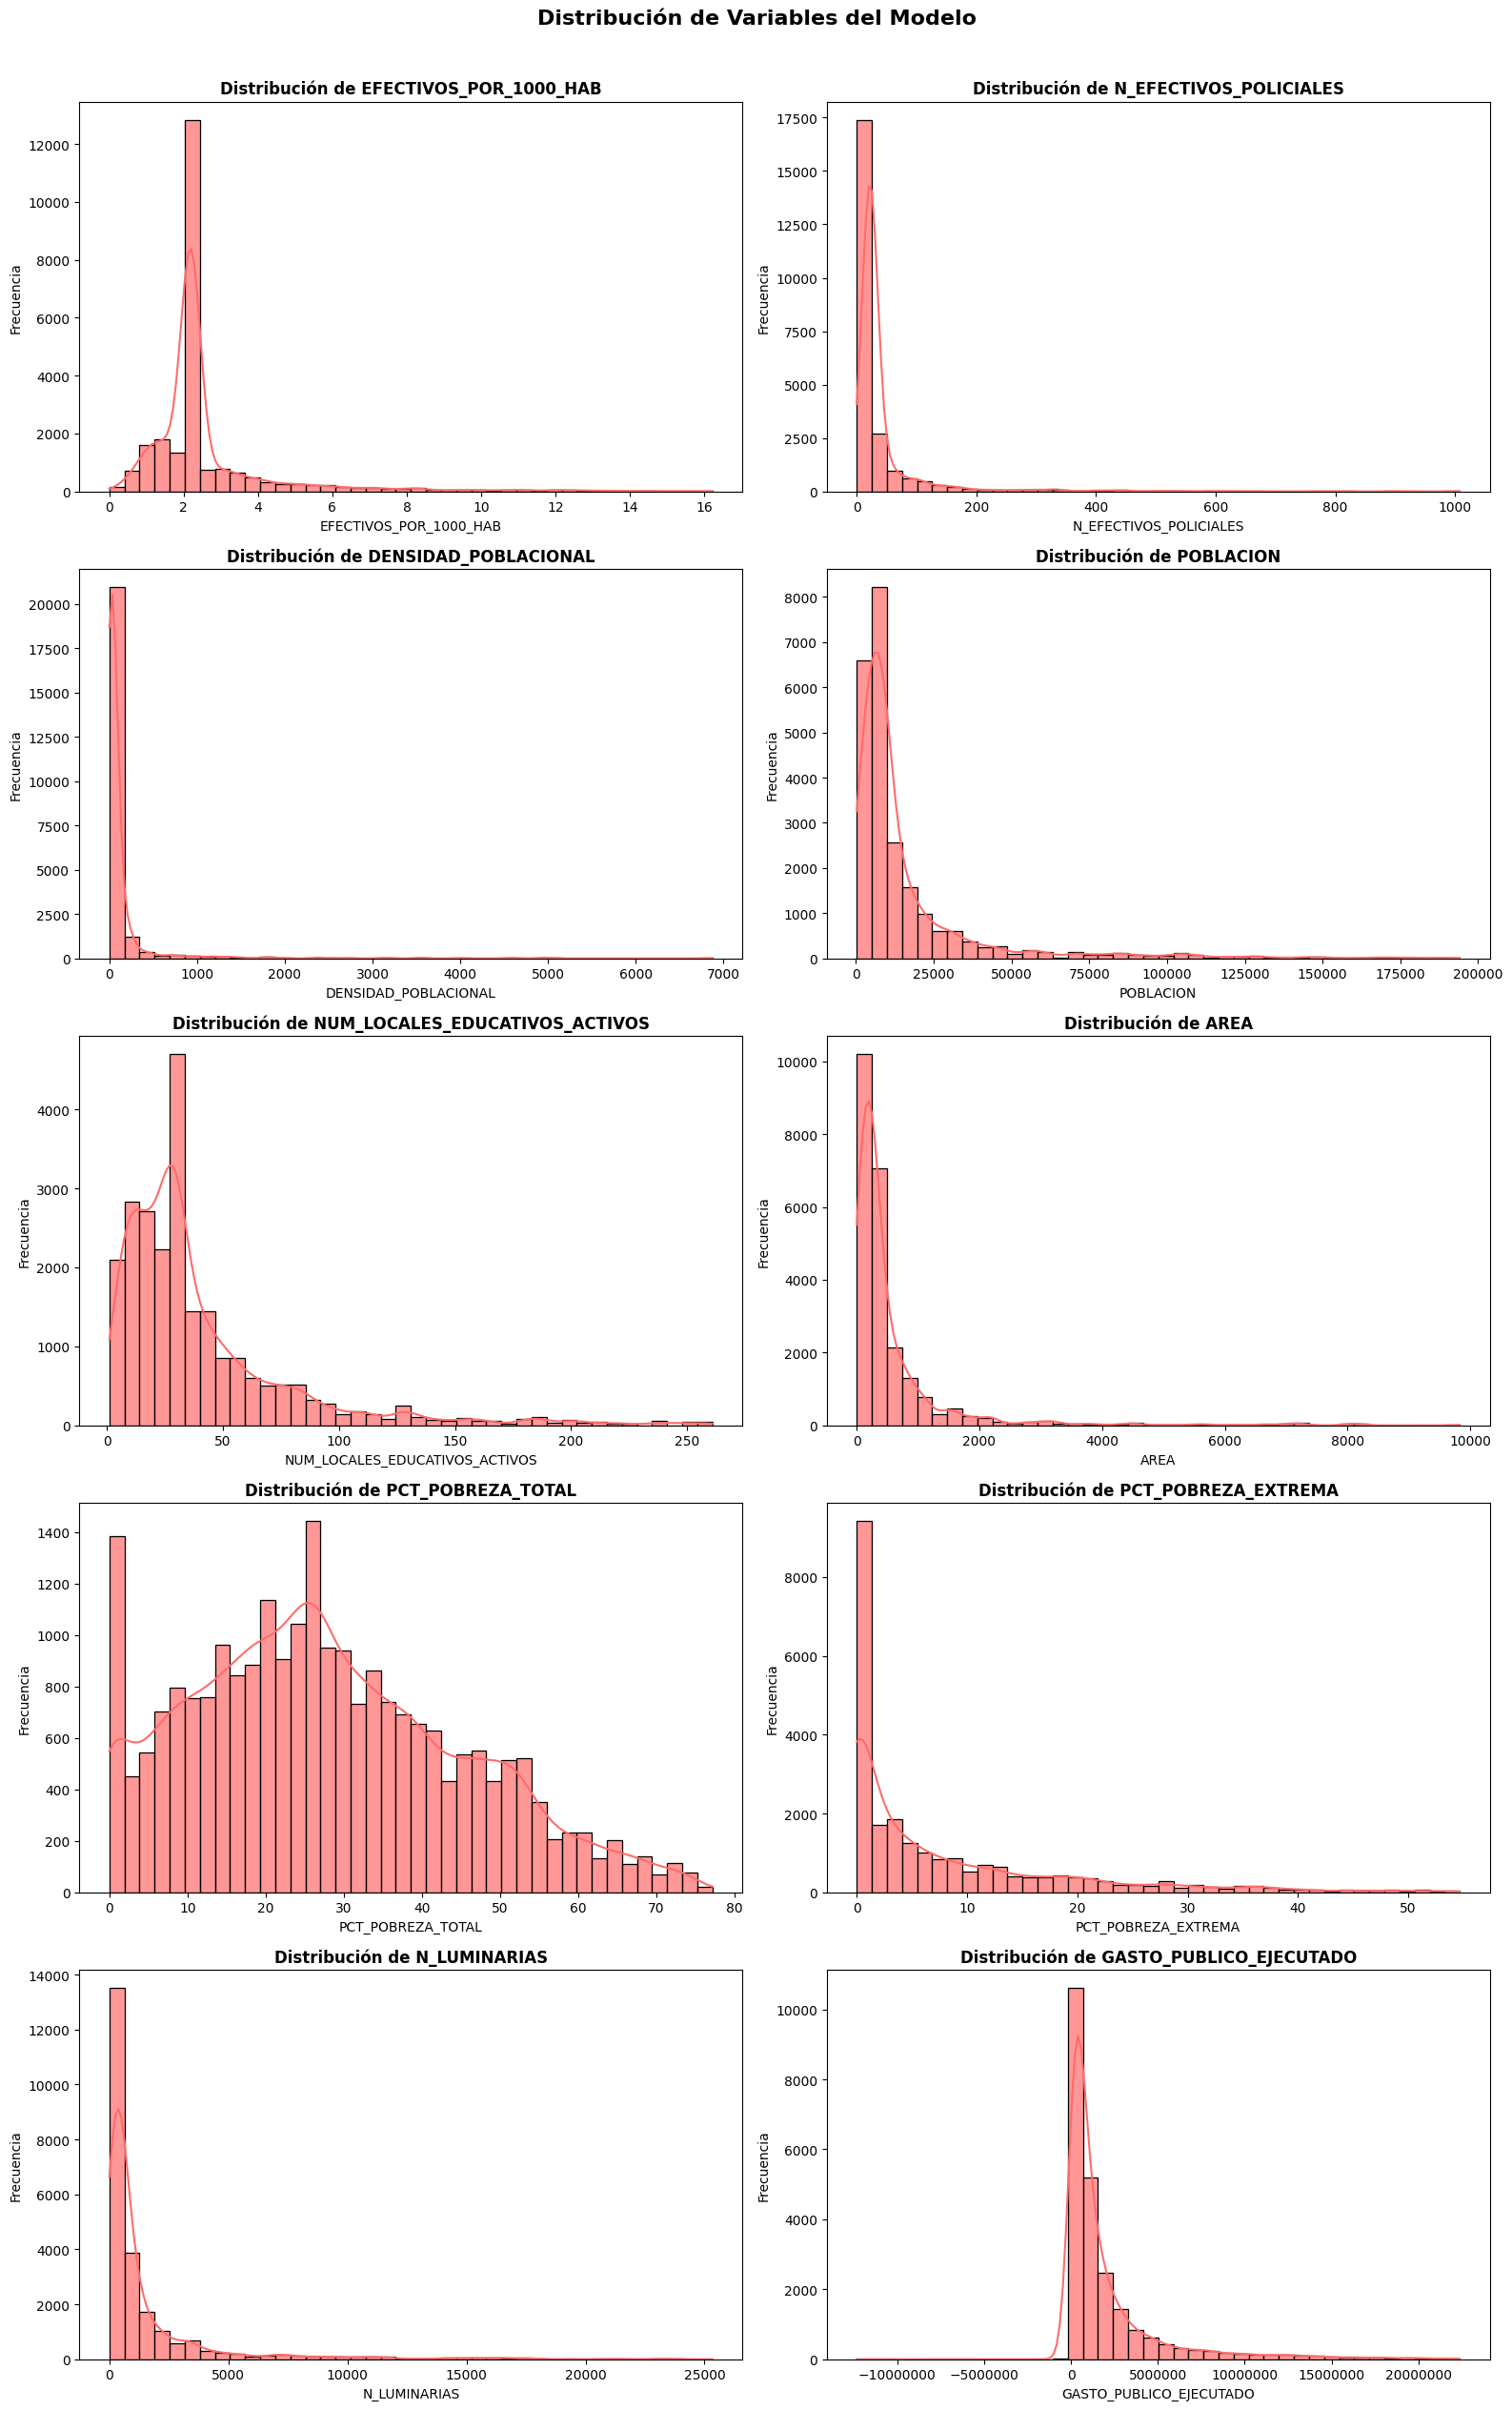

In [162]:
import matplotlib.pyplot as plt
import seaborn as sns

variables = [
    "EFECTIVOS_POR_1000_HAB",
    "N_EFECTIVOS_POLICIALES",
    "DENSIDAD_POBLACIONAL",
    "POBLACION",
    "NUM_LOCALES_EDUCATIVOS_ACTIVOS",
    "AREA",
    "PCT_POBREZA_TOTAL",
    "PCT_POBREZA_EXTREMA",
    "N_LUMINARIAS",
    "GASTO_PUBLICO_EJECUTADO"
]

# Convertir a numéricas
for col in variables:
    df_imputed[col] = pd.to_numeric(df_imputed[col], errors="coerce")

# Crear figura dinámica
n_vars = len(variables)
n_cols = 2
n_rows = (n_vars + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(16, 5 * n_rows))
axes = axes.flatten()

# Crear histogramas
for i, col in enumerate(variables):

    datos = df_imputed[col].dropna()

    # Limitar visualización al percentil 99
    p99 = datos.quantile(0.99)
    datos_vis = datos[datos <= p99]

    sns.histplot(
        datos_vis,
        bins=40,
        kde=True,
        ax=axes[i],
        color="#FF6B6B",
        alpha=0.7
    )

    axes[i].set_title(
        f"Distribución de {col}",
        fontweight="bold",
        fontsize=12
    )

    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frecuencia")

    axes[i].ticklabel_format(
        style="plain",
        axis="x"
    )

# Eliminar espacios sobrantes
for j in range(n_vars, len(axes)):
    fig.delaxes(axes[j])

plt.suptitle(
    "Distribución de Variables del Modelo",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

### 2.5. Detección de valores atípicos mediante puntuación Z (Z-Score > 3)
Se cuantifica la cantidad y porcentaje de observaciones atípicas por variable empleando el criterio de tres desviaciones estándar.

In [163]:
import numpy as np
from scipy import stats

# Calcular Z-scores únicamente de variables numéricas
z_scores = pd.DataFrame(
    np.abs(stats.zscore(df_imputed[features], nan_policy="omit")),
    columns=features,
    index=df_imputed.index
)

# Detectar outliers (Z-score > 3)
outliers_z_score = z_scores > 3

In [164]:
outliers_by_col = outliers_z_score.sum(axis=0)

outliers_summary = pd.DataFrame({
    'Columna': outliers_by_col.index,
    'Outliers': outliers_by_col.values,
    'Porcentaje (%)': (outliers_by_col.values / len(df_imputed) * 100).round(2)
})

outliers_summary.sort_values('Outliers', ascending=False)

,Columna,Outliers,Porcentaje (%)
0,EFECTIVOS_POR_1000_HAB,609,2.55
4,NUM_LOCALES_EDUCATIVOS_ACTIVOS,599,2.50
7,PCT_POBREZA_EXTREMA,579,2.42
3,POBLACION,564,2.36
5,AREA,495,2.07
8,N_LUMINARIAS,460,1.92
1,N_EFECTIVOS_POLICIALES,257,1.07
2,DENSIDAD_POBLACIONAL,252,1.05
9,GASTO_PUBLICO_EJECUTADO,128,0.54
6,PCT_POBREZA_TOTAL,119,0.50


### 2.6. Visualización de valores atípicos mediante rango intercuartílico (IQR)
Se generan diagramas de caja (*boxplots*) para inspeccionar la dispersión y el número de *outliers* fuera de los límites $[Q_1 - 1.5 \cdot IQR,\; Q_3 + 1.5 \cdot IQR]$.

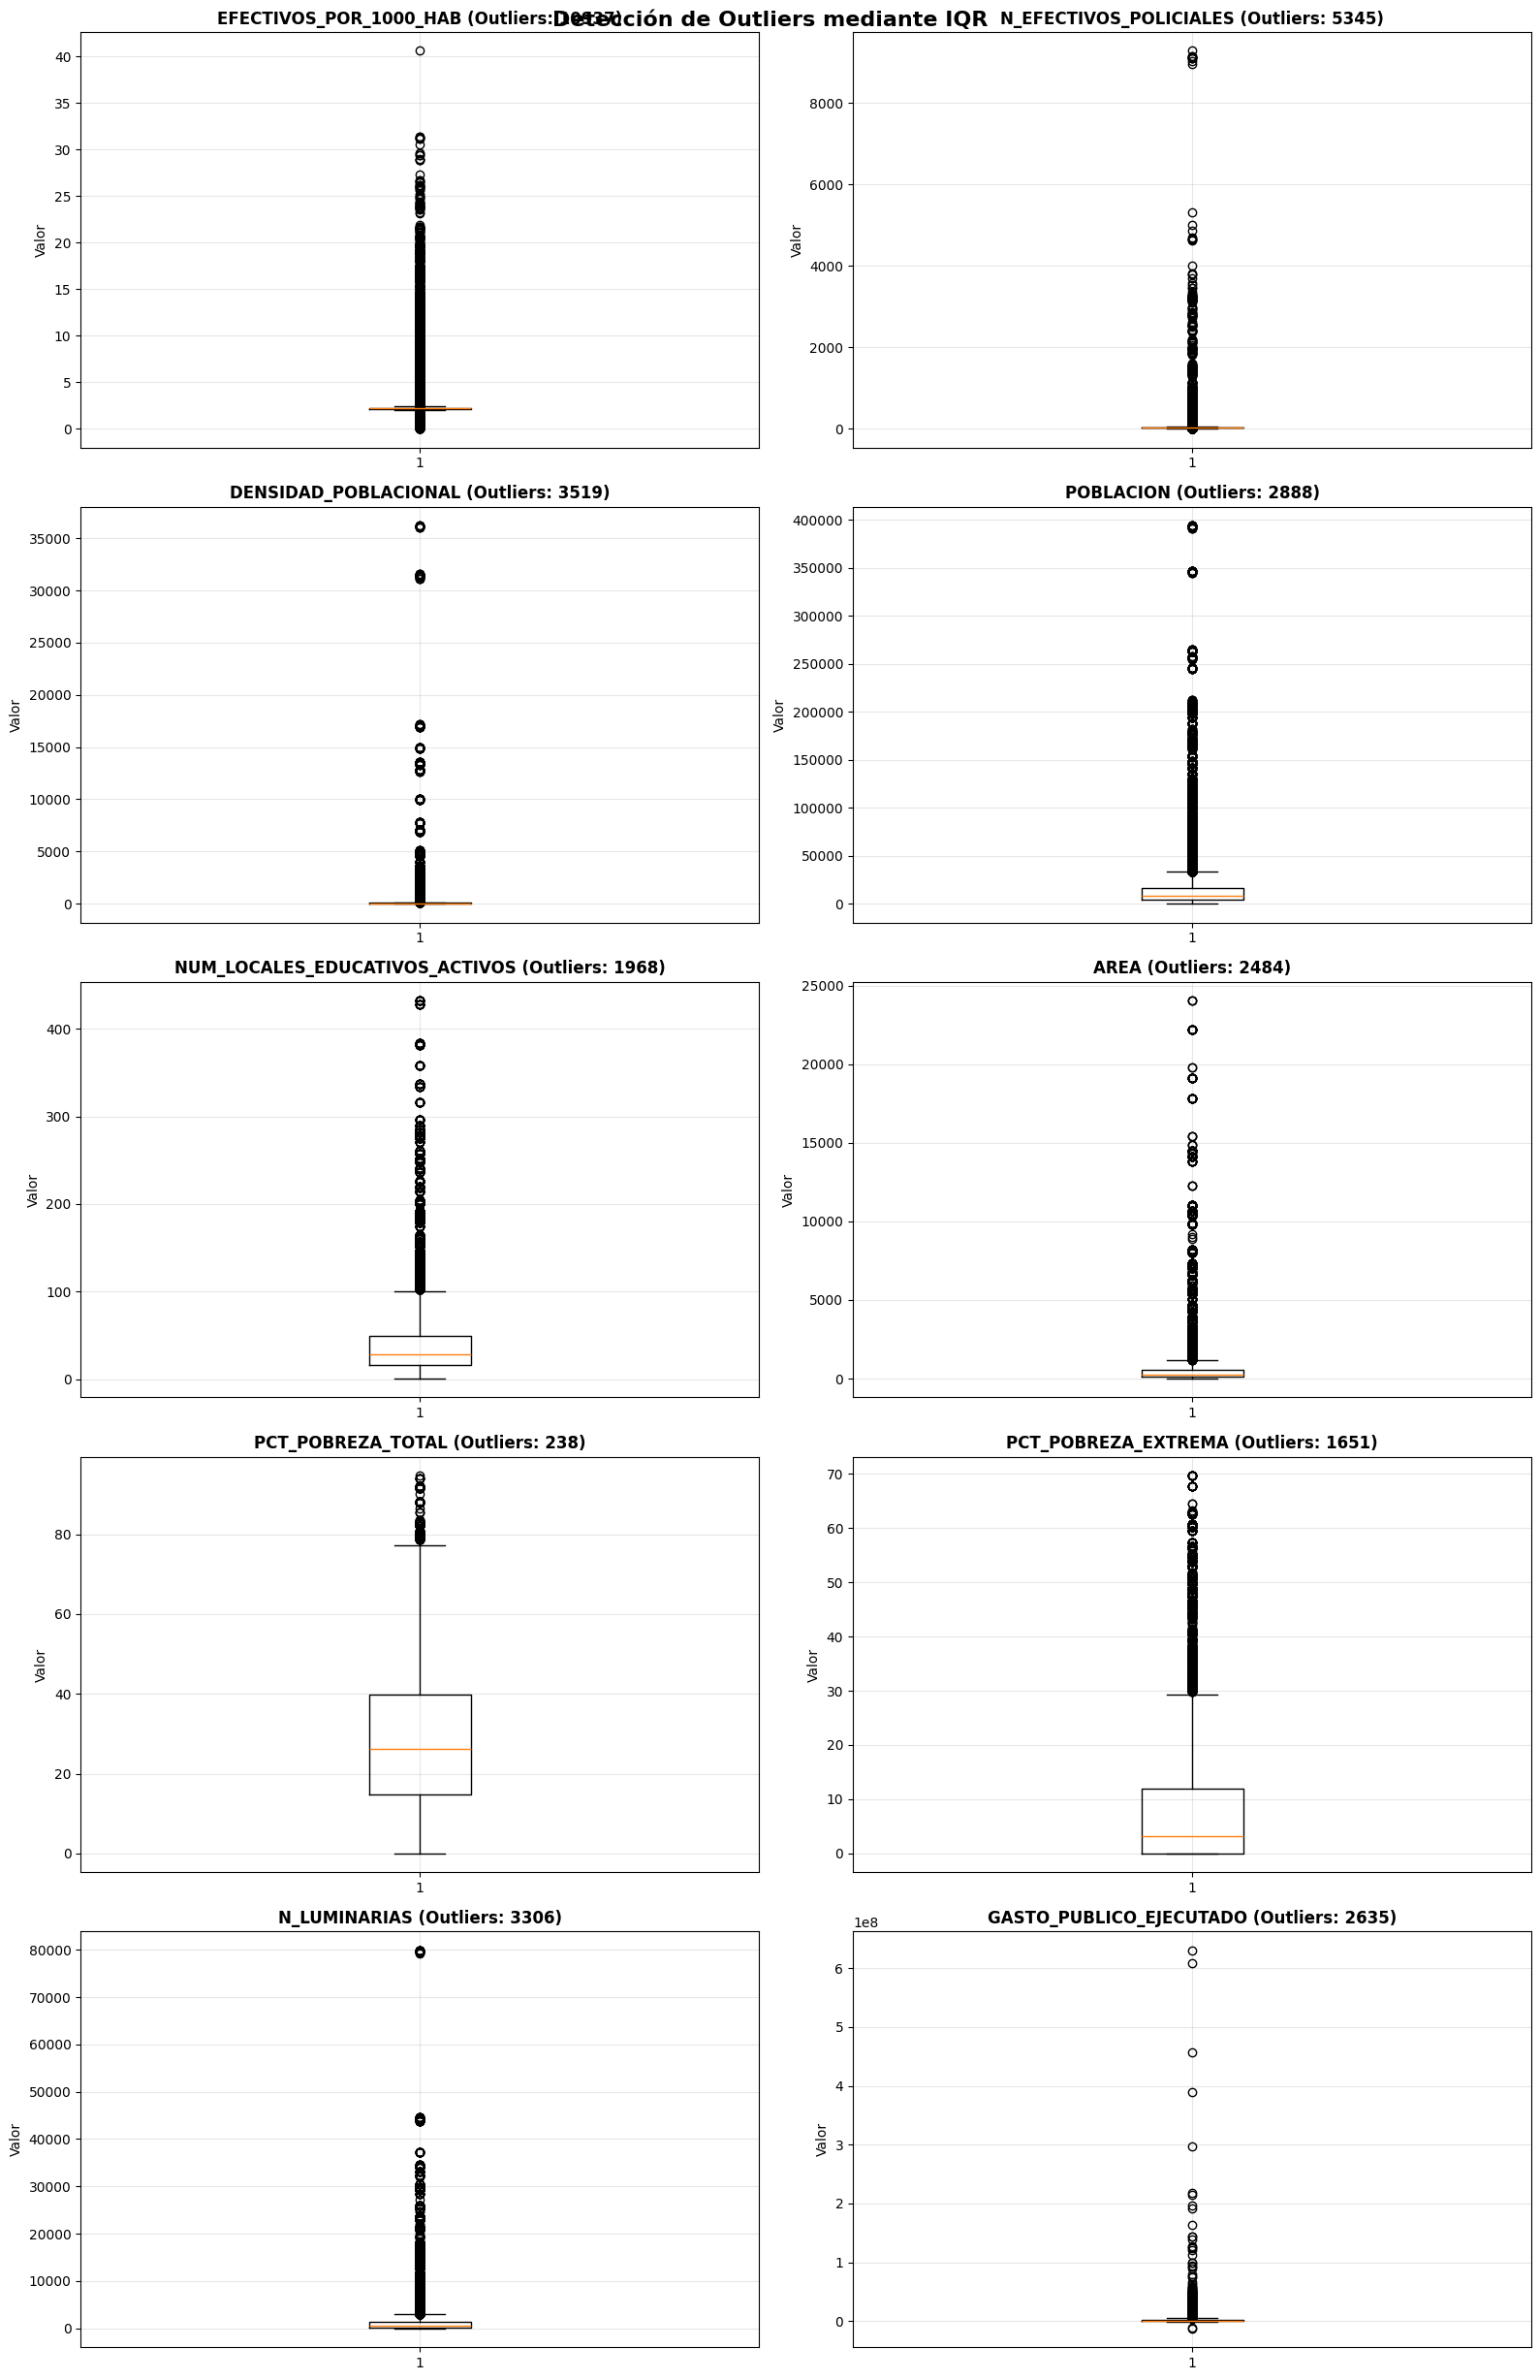

In [165]:
def plot_boxplots(df, features, title='Boxplots'):

    n_vars = len(features)
    n_cols = 2
    n_rows = (n_vars + n_cols - 1) // n_cols

    fig, axes = plt.subplots(
        n_rows, n_cols,
        figsize=(16, 5 * n_rows)
    )

    axes = np.array(axes).flatten()

    for i, col in enumerate(features):

        datos = df[col].dropna()

        axes[i].boxplot(datos, vert=True)

        Q1 = datos.quantile(0.25)
        Q3 = datos.quantile(0.75)
        IQR = Q3 - Q1

        outlier_count = (
            (datos < Q1 - 1.5 * IQR) |
            (datos > Q3 + 1.5 * IQR)
        ).sum()

        axes[i].set_title(
            f'{col} (Outliers: {outlier_count})',
            fontweight='bold'
        )

        axes[i].set_ylabel('Valor')
        axes[i].grid(alpha=0.3)

    # Eliminar espacios sobrantes
    for j in range(n_vars, len(axes)):
        fig.delaxes(axes[j])

    plt.suptitle(title, fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()


# Ejecutar
plot_boxplots(
    df_imputed,
    features,
    title='Detección de Outliers mediante IQR'
)

### 2.7. Tratamiento de valores atípicos mediante acotamiento (Clipping IQR)
Se genera una copia independiente (`df_clipped`) acotando los valores extremos dentro de los límites $[Q_1 - 1.5 \cdot IQR,\; Q_3 + 1.5 \cdot IQR]$ para evaluar posteriormente el impacto del recorte frente al dataset con valores originales (`df_imputed`) escalados de forma robusta.

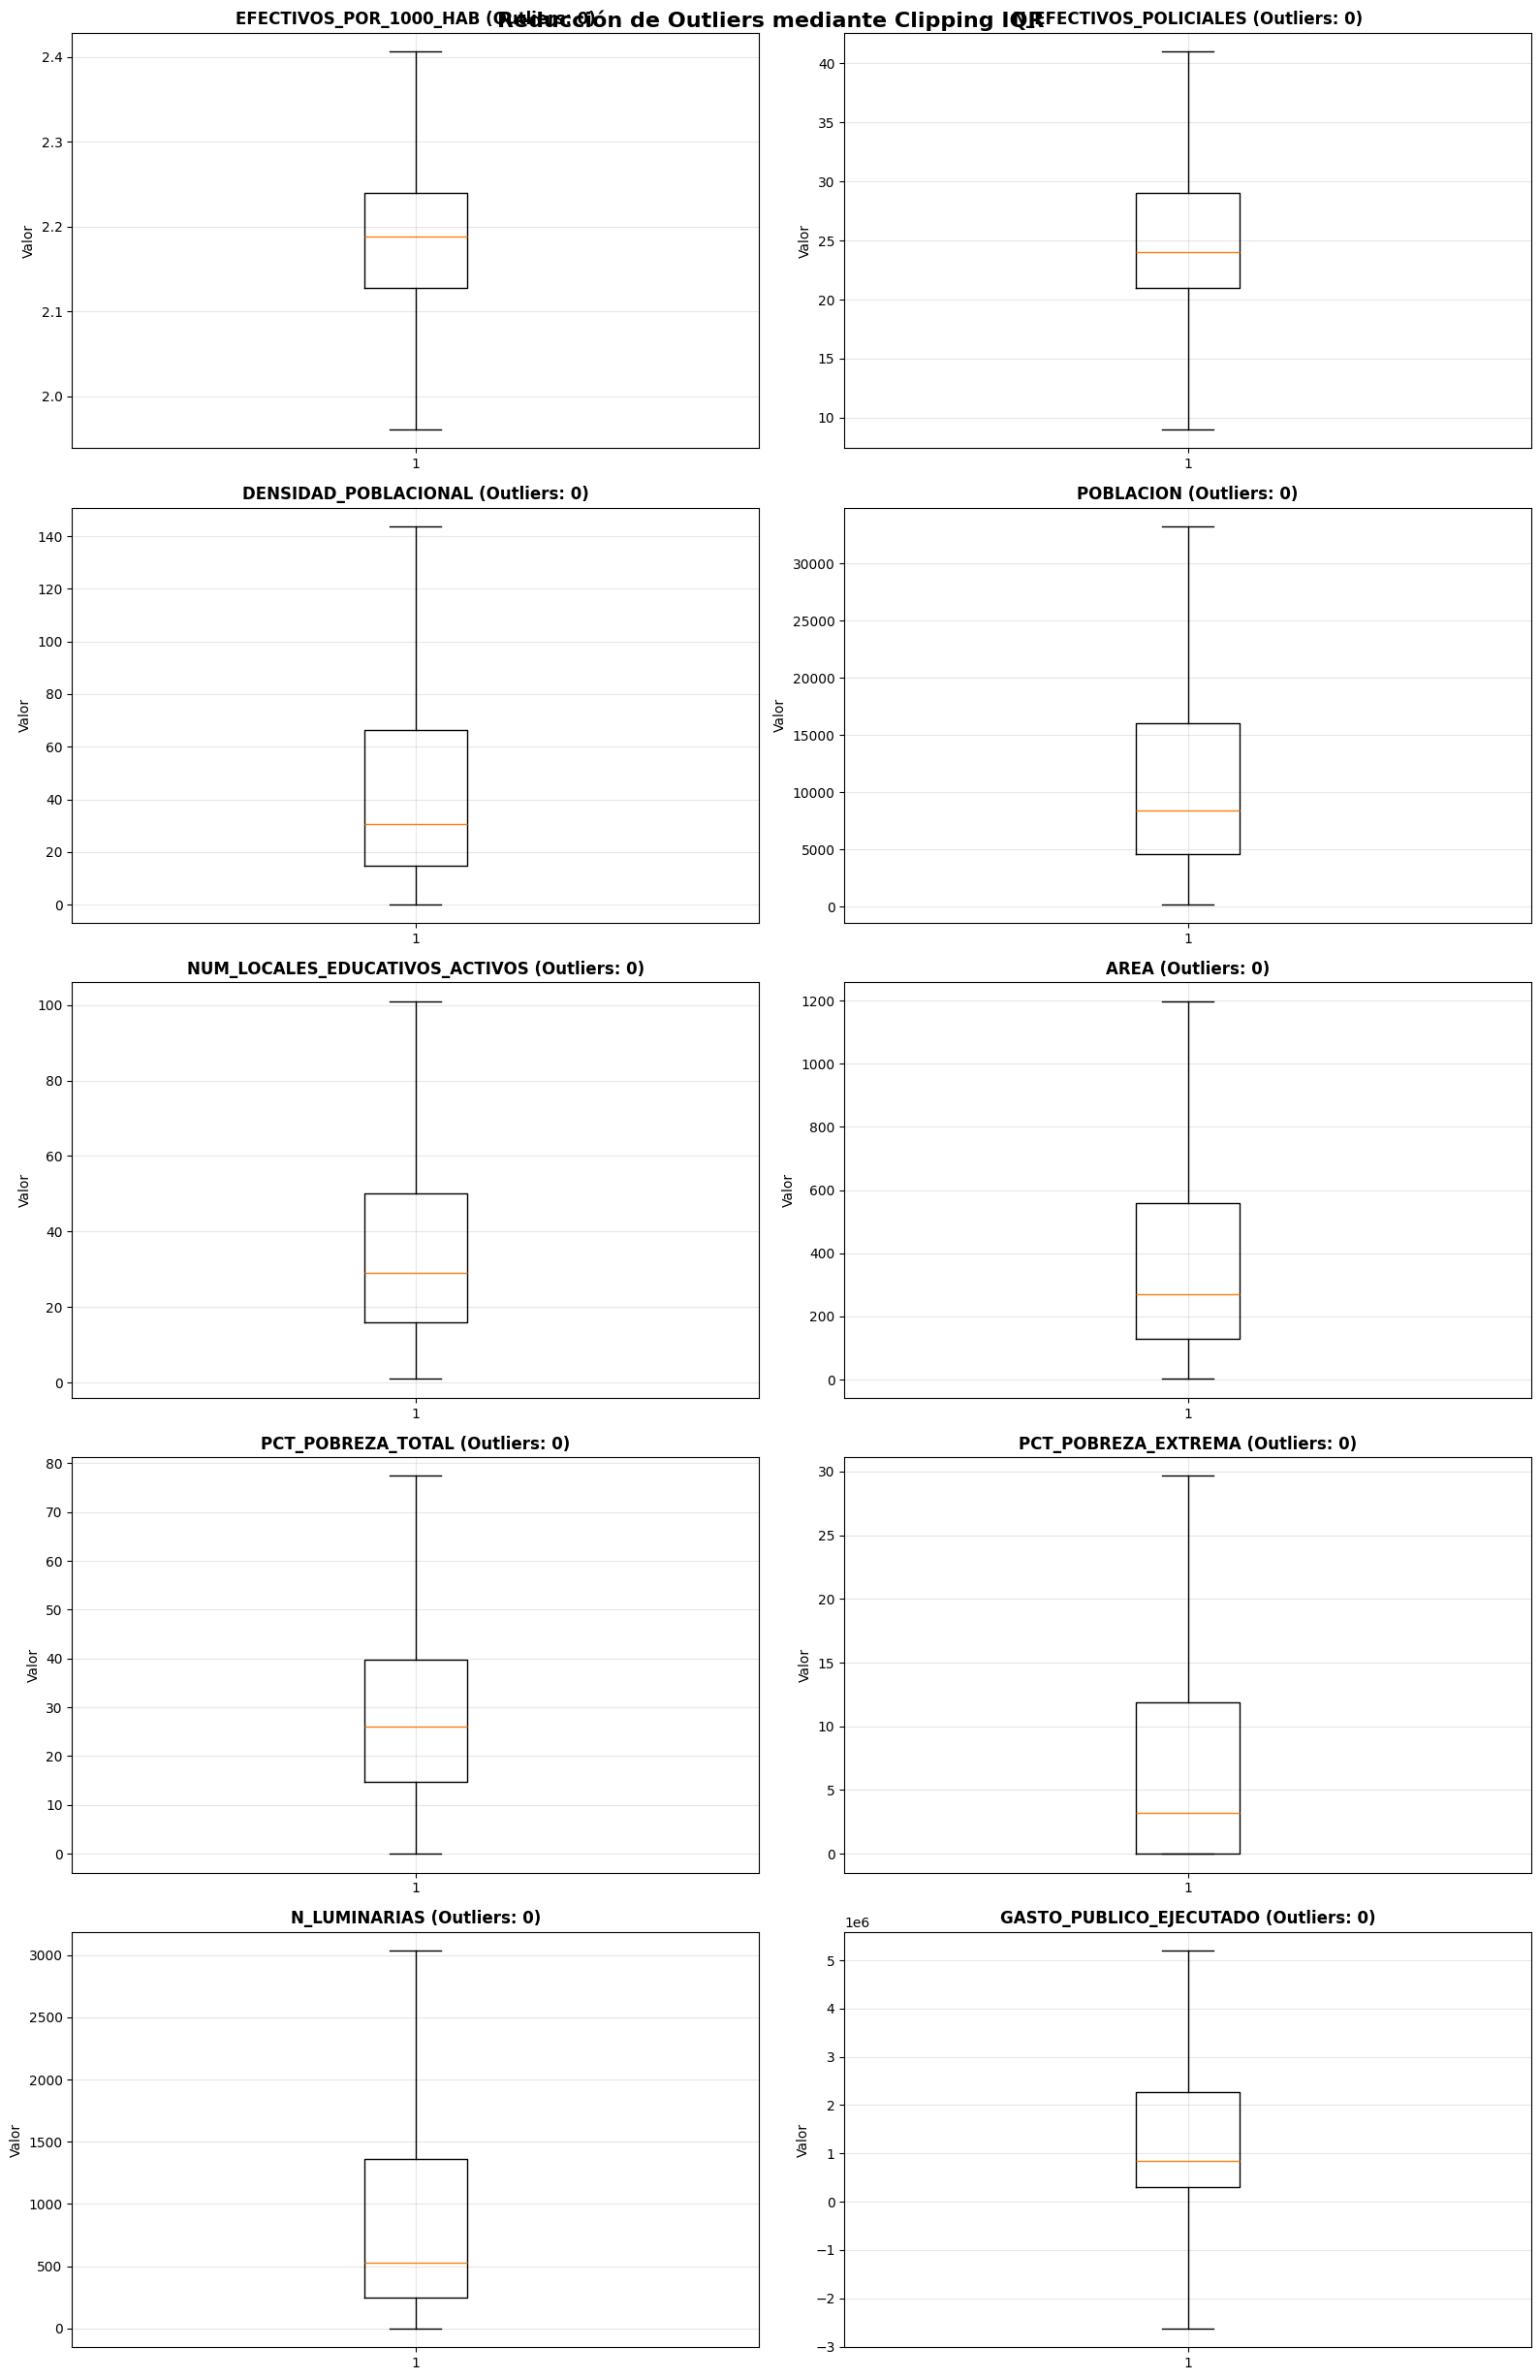

In [166]:
# Crear copia independiente para no sobrescribir los valores reales de Lima en df_imputed
df_clipped = df_imputed.copy()

for col in features:
    Q1 = df_clipped[col].quantile(0.25)
    Q3 = df_clipped[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    df_clipped[col] = df_clipped[col].clip(lower=lower_bound, upper=upper_bound)

plot_boxplots(
    df_clipped,
    features,
    title='Reducción de Outliers mediante Clipping IQR'
)

In [167]:
plt.suptitle(
    "Distribución de Variables del Modelo",
    fontsize=16,
    fontweight="bold",
    y=1.01
)

plt.tight_layout()
plt.show()

<Figure size 640x480 with 0 Axes>

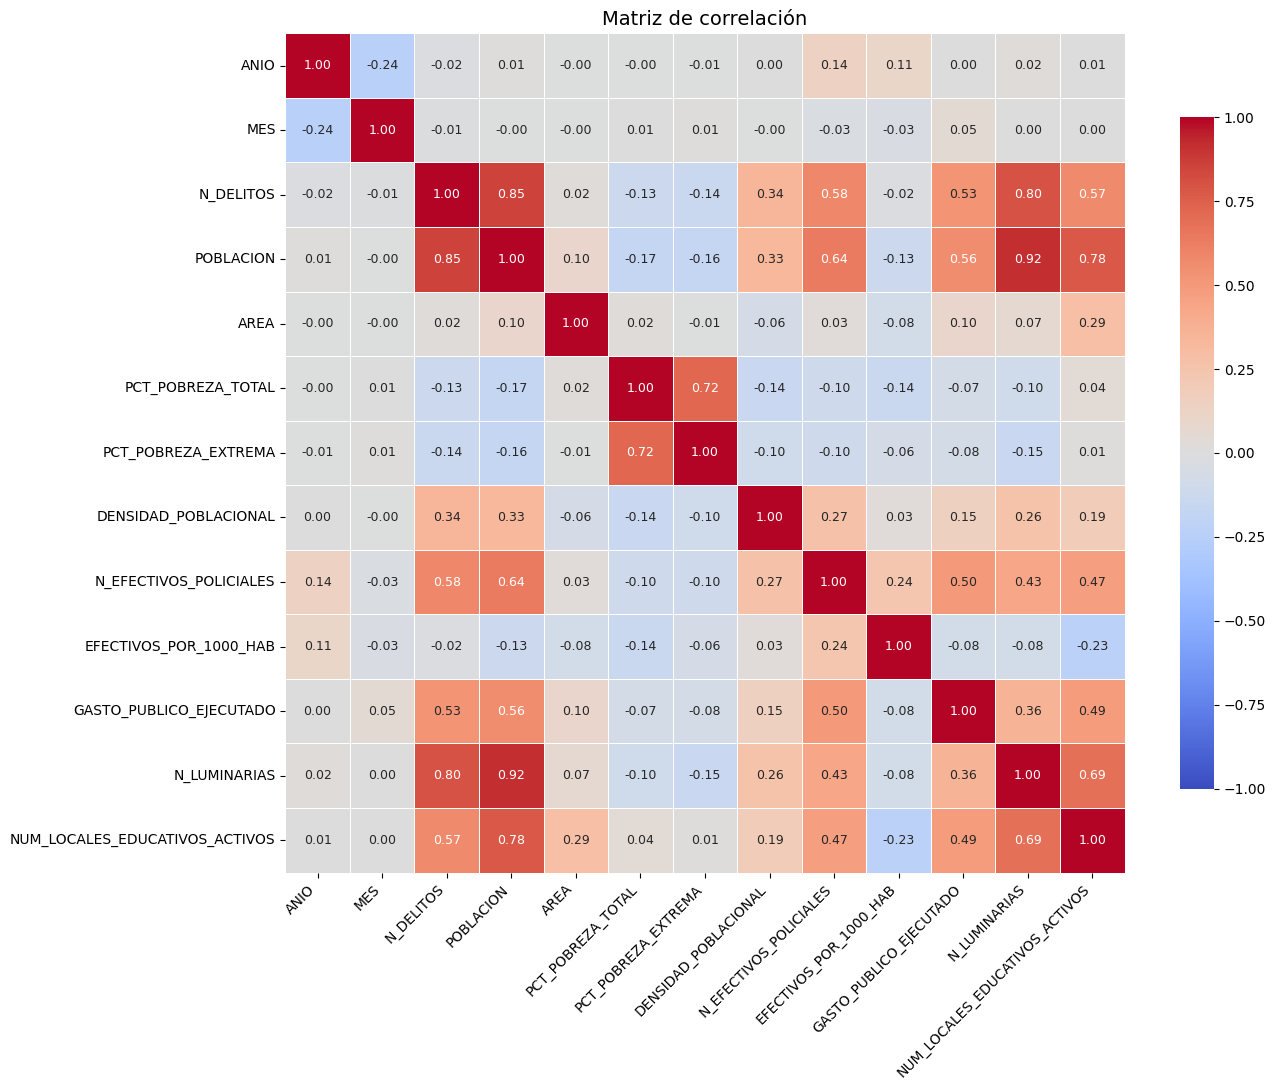

In [168]:
df_corr = df.select_dtypes(include='number').corr()

# Ocultar el triángulo superior (es redundante, la matriz es simétrica)
mascara = np.triu(np.ones_like(df_corr, dtype=bool))

plt.figure(figsize=(14, 11))
sns.heatmap(
    df_corr,
    annot=True,
    fmt='.2f',                 # solo 2 decimales (evita 0.00063, etc.)
    annot_kws={'size': 9},
    cmap='coolwarm',           # divergente: distingue correlación + y -
    center=0,
    vmin=-1, vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={'shrink': 0.8}
)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.title('Matriz de correlación', fontsize=14)
plt.tight_layout()
plt.show()

## 3. Ingeniería de Características y Partición Temporal
Preparación del panel espaciotemporal para el entrenamiento supervisado sin fuga de datos (*data leakage*).

### 3.1. Creación de rezagos autorregresivos (Lags 1–3) y media móvil trimestral
Ordenando `df_imputed` por `UBIGEO`, `ANIO` y `MES`, se calculan los conteos delictivos de los tres meses previos (`delitos_lag_1`, `delitos_lag_2`, `delitos_lag_3`) y el promedio móvil trimestral (`delitos_roll_mean_3`) por distrito.

In [169]:
def crear_variables_temporales(dataframe):
    df_temp = dataframe.sort_values(['UBIGEO', 'ANIO', 'MES']).copy()

    # Rezagos de 1, 2 y 3 meses anteriores por distrito
    for lag in [1, 2, 3]:
        df_temp[f'delitos_lag_{lag}'] = df_temp.groupby('UBIGEO')['N_DELITOS'].shift(lag)

    # Media móvil de los 3 meses previos (sin incluir el mes actual)
    df_temp['delitos_roll_mean_3'] = (
        df_temp.groupby('UBIGEO')['N_DELITOS']
        .transform(lambda x: x.shift(1).rolling(3).mean())
    )

    # Eliminar los primeros 3 meses por distrito sin historial completo
    return df_temp.dropna(subset=['delitos_lag_3']).reset_index(drop=True)

df_model = crear_variables_temporales(df_imputed)
df_model_clipped = crear_variables_temporales(df_clipped)

print(f"Registros listos para modelado (Abr 2024 - Sep 2025): {len(df_model):,}")
df_model[['ANIO', 'MES', 'UBIGEO', 'DISTRITO', 'N_DELITOS', 'delitos_lag_1', 'delitos_lag_2', 'delitos_roll_mean_3']].head()

Registros listos para modelado (Abr 2024 - Sep 2025): 18,927


,ANIO,MES,UBIGEO,DISTRITO,N_DELITOS,delitos_lag_1,delitos_lag_2,delitos_roll_mean_3
0,2024,4,010101,CHACHAPOYAS,111,87.0,66.0,78.000000
1,2024,5,010101,CHACHAPOYAS,95,111.0,87.0,88.000000
2,2024,6,010101,CHACHAPOYAS,108,95.0,111.0,97.666667
3,2024,7,010101,CHACHAPOYAS,90,108.0,95.0,104.666667
4,2024,8,010101,CHACHAPOYAS,111,90.0,108.0,97.666667


### 3.2. Definición de escenarios de ablación y partición temporal (Train / Test)
Se establecen dos escenarios de variables predictoras para medir el aporte de las fuentes externas: **Escenario A** (únicamente mes e historial delictivo) y **Escenario B** (historial delictivo + las 10 variables multisectoriales). Asimismo, se realiza una división cronológica estricta en **Entrenamiento** (abril 2024 – junio 2025) y **Prueba** (julio – septiembre 2025).

In [170]:
# Definición de conjuntos de variables (Estudio de Ablación)
features_escenario_A = [
    'MES', 'delitos_lag_1', 'delitos_lag_2', 'delitos_lag_3', 'delitos_roll_mean_3'
]

features_escenario_B = features_escenario_A + [
    'POBLACION', 'AREA', 'PCT_POBREZA_TOTAL', 'PCT_POBREZA_EXTREMA',
    'DENSIDAD_POBLACIONAL', 'N_EFECTIVOS_POLICIALES', 'EFECTIVOS_POR_1000_HAB',
    'GASTO_PUBLICO_EJECUTADO', 'N_LUMINARIAS', 'NUM_LOCALES_EDUCATIVOS_ACTIVOS'
]

# Detectar automáticamente los últimos 3 periodos (ANIO, MES) disponibles en df_model
periodos_unicos = (
    df_model[['ANIO', 'MES']]
    .drop_duplicates()
    .sort_values(['ANIO', 'MES'])
    .reset_index(drop=True)
)

ultimos_3_periodos = periodos_unicos.tail(3)
print("Periodos reservados para Prueba (Test - últimos 3 meses disponibles):")
print(ultimos_3_periodos.to_string(index=False))

# Crear máscara de prueba dinámica
mask_test = df_model.set_index(['ANIO', 'MES']).index.isin(
    ultimos_3_periodos.set_index(['ANIO', 'MES']).index
)

train_df = df_model[~mask_test].copy()
test_df = df_model[mask_test].copy()

train_clip_df = df_model_clipped[~mask_test].copy()
test_clip_df = df_model_clipped[mask_test].copy()

print(f"\nConjunto de Entrenamiento: {len(train_df):,} filas ({len(train_df)/len(df_model)*100:.1f}%)")
print(f"Conjunto de Prueba:        {len(test_df):,} filas ({len(test_df)/len(df_model)*100:.1f}%)")

Periodos reservados para Prueba (Test - últimos 3 meses disponibles):
 ANIO  MES
 2025    7
 2025    8
 2025    9

Conjunto de Entrenamiento: 15,713 filas (83.0%)
Conjunto de Prueba:        3,214 filas (17.0%)


### 3.3. Construcción de etiquetas de nivel de riesgo distrital (Bajo, Medio, Alto)
A partir de los terciles (percentiles 33% y 66%) de la incidencia delictiva calculados exclusivamente en el conjunto de entrenamiento, se discretiza la variable objetivo en tres categorías de prioridad distrital (`Bajo`, `Medio`, `Alto`) para la etapa de clasificación.

In [171]:
# Calcular umbrales de corte SOLO sobre entrenamiento para evitar fuga de datos
q33, q66 = train_df['N_DELITOS'].quantile([0.33, 0.66])
print(f"Umbrales de clasificación (Train) -> Bajo: <= {q33:.0f} | Medio: ({q33:.0f}, {q66:.0f}] | Alto: > {q66:.0f}")

def asignar_nivel_riesgo(serie):
    return pd.cut(
        serie,
        bins=[-np.inf, q33, q66, np.inf],
        labels=['Bajo', 'Medio', 'Alto']
    )

y_train_clf = asignar_nivel_riesgo(train_df['N_DELITOS'])
y_test_clf = asignar_nivel_riesgo(test_df['N_DELITOS'])

print("\nDistribución de clases en Prueba (Jul - Sep 2025):")
print(y_test_clf.value_counts())

Umbrales de clasificación (Train) -> Bajo: <= 3 | Medio: (3, 14] | Alto: > 14

Distribución de clases en Prueba (Jul - Sep 2025):
N_DELITOS
Bajo     1290
Alto      972
Medio     952
Name: count, dtype: int64


## 4. Etapa 1: Predicción de la Cantidad de Delitos
Evaluación comparativa de modelos supervisados para estimar el conteo mensual exacto de denuncias (`N_DELITOS`), contrastando el aporte de las variables multisectoriales frente a un modelo base de persistencia ($\hat{y}_t = y_{t-1}$).

### 4.1. Entrenamiento y evaluación en Escenario A (Solo inercia delictiva)
Se evalúa el modelo base de persistencia frente a Regresión Lineal, Árbol de Regresión (CART), KNN para Regresión y Perceptrón Multicapa (`MLPRegressor`) con escalamiento robusto (`RobustScaler`), utilizando exclusivamente el mes y los rezagos históricos de denuncias.

In [172]:
from sklearn.preprocessing import RobustScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score

def calcular_wape(y_real, y_pred):
    return (np.sum(np.abs(y_real - y_pred)) / np.sum(y_real)) * 100

def evaluar_modelos_regresion(X_tr, y_tr, X_te, y_te, lag1_te, etiqueta_escenario):
    modelos = {
        "Baseline (Persistencia Lag 1)": None,
        "Regresión Lineal": make_pipeline(RobustScaler(), LinearRegression()),
        "Árbol de Regresión (CART)": DecisionTreeRegressor(max_depth=8, min_samples_leaf=10, random_state=42),
        "KNN Regresión": make_pipeline(RobustScaler(), KNeighborsRegressor(n_neighbors=7, weights='distance')),
        "MLP Regressor": make_pipeline(
            RobustScaler(),
            MLPRegressor(hidden_layer_sizes=(64, 32), max_iter=300, early_stopping=True, random_state=42)
        )
    }

    resultados = []
    predicciones_dict = {}

    for nombre, modelo in modelos.items():
        if modelo is None:
            y_pred = lag1_te.values
        else:
            modelo.fit(X_tr, y_tr)
            # Evitar conteos negativos de delitos
            y_pred = np.clip(modelo.predict(X_te), 0, None)

        predicciones_dict[nombre] = y_pred
        resultados.append({
            "Escenario": etiqueta_escenario,
            "Modelo": nombre,
            "MAE": round(mean_absolute_error(y_te, y_pred), 3),
            "RMSE": round(root_mean_squared_error(y_te, y_pred), 3),
            "R2": round(r2_score(y_te, y_pred), 4),
            "WAPE (%)": round(calcular_wape(y_te, y_pred), 2)
        })

    return pd.DataFrame(resultados), predicciones_dict

y_train_reg = train_df['N_DELITOS']
y_test_reg = test_df['N_DELITOS']

df_res_reg_A, preds_reg_A = evaluar_modelos_regresion(
    train_df[features_escenario_A], y_train_reg,
    test_df[features_escenario_A], y_test_reg,
    test_df['delitos_lag_1'],
    "Escenario A (Solo Historia)"
)

display(df_res_reg_A.sort_values("MAE"))

,Escenario,Modelo,MAE,RMSE,R2,WAPE (%)
1,Escenario A (Solo Historia),Regresión Lineal,6.427,16.034,0.9850,15.84
4,Escenario A (Solo Historia),MLP Regressor,6.612,17.191,0.9828,16.30
0,Escenario A (Solo Historia),Baseline (Persistencia Lag 1),6.854,17.073,0.9830,16.90
3,Escenario A (Solo Historia),KNN Regresión,7.057,18.434,0.9802,17.40
2,Escenario A (Solo Historia),Árbol de Regresión (CART),7.193,21.953,0.9719,17.73


### 4.2. Entrenamiento y evaluación en Escenario B (Dataset consolidado multisectorial)
Se entrenan los mismos algoritmos incorporando las 10 variables demográficas, socioeconómicas, policiales, presupuestales y de infraestructura urbana para cuantificar la mejora en precisión predictiva respecto al Escenario A. Asimismo, se verifica el efecto del tratamiento de valores atípicos (`df_clipped` vs. `df_imputed`).

In [173]:
# Evaluación con dataset completo sin clipping destructivo (df_imputed + RobustScaler)
df_res_reg_B, preds_reg_B = evaluar_modelos_regresion(
    train_df[features_escenario_B], y_train_reg,
    test_df[features_escenario_B], y_test_reg,
    test_df['delitos_lag_1'],
    "Escenario B (Consolidado)"
)

# Evaluación comparativa con dataset acotado por IQR (df_clipped)
df_res_reg_B_clip, _ = evaluar_modelos_regresion(
    train_clip_df[features_escenario_B], y_train_reg,
    test_clip_df[features_escenario_B], y_test_reg,
    test_clip_df['delitos_lag_1'],
    "Escenario B (Con Clipping IQR)"
)

print("=== RESULTADOS ESCENARIO B (DATASET CONSOLIDADO SIN CLIPPING) ===")
display(df_res_reg_B.sort_values("MAE"))

print("\n=== COMPARATIVA TRATAMIENTO DE OUTLIERS (CON CLIPPING IQR) ===")
display(df_res_reg_B_clip.sort_values("MAE"))

=== RESULTADOS ESCENARIO B (DATASET CONSOLIDADO SIN CLIPPING) ===


,Escenario,Modelo,MAE,RMSE,R2,WAPE (%)
1,Escenario B (Consolidado),Regresión Lineal,6.625,16.904,0.9834,16.33
4,Escenario B (Consolidado),MLP Regressor,6.716,18.531,0.9800,16.56
0,Escenario B (Consolidado),Baseline (Persistencia Lag 1),6.854,17.073,0.9830,16.90
2,Escenario B (Consolidado),Árbol de Regresión (CART),7.566,22.914,0.9694,18.65
3,Escenario B (Consolidado),KNN Regresión,9.353,38.761,0.9125,23.06



=== COMPARATIVA TRATAMIENTO DE OUTLIERS (CON CLIPPING IQR) ===


,Escenario,Modelo,MAE,RMSE,R2,WAPE (%)
4,Escenario B (Con Clipping IQR),MLP Regressor,6.440,15.881,0.9853,15.88
1,Escenario B (Con Clipping IQR),Regresión Lineal,6.444,16.016,0.9851,15.88
0,Escenario B (Con Clipping IQR),Baseline (Persistencia Lag 1),6.854,17.073,0.9830,16.90
3,Escenario B (Con Clipping IQR),KNN Regresión,7.031,18.437,0.9802,17.33
2,Escenario B (Con Clipping IQR),Árbol de Regresión (CART),7.345,22.297,0.9710,18.11


### 4.3. Ajuste de hiperparámetros (Optimización de Árboles y KNN)
Se realiza una búsqueda sistemática de hiperparámetros sobre el conjunto de entrenamiento utilizando validación temporal (`TimeSeriesSplit`) para optimizar la profundidad máxima del Árbol de Regresión (`max_depth`, `min_samples_leaf`) y el número de vecinos y métrica de distancia en KNN (`n_neighbors`, `p`).

In [174]:
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

# Ordenar cronológicamente train_df para validación cruzada temporal sin fuga
train_sorted = train_df.sort_values(['ANIO', 'MES', 'UBIGEO']).reset_index(drop=True)
X_tr_opt = train_sorted[features_escenario_B]
y_tr_opt = train_sorted['N_DELITOS']

tscv = TimeSeriesSplit(n_splits=4)

# 1. Optimización de Árbol de Regresión (CART)
grid_tree_reg = GridSearchCV(
    DecisionTreeRegressor(random_state=42),
    param_grid={
        'max_depth': [5, 8, 10, 12],
        'min_samples_leaf': [5, 10, 20]
    },
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)
grid_tree_reg.fit(X_tr_opt, y_tr_opt)

# 2. Optimización de KNN Regresión
pipe_knn_reg = make_pipeline(RobustScaler(), KNeighborsRegressor())
grid_knn_reg = GridSearchCV(
    pipe_knn_reg,
    param_grid={
        'kneighborsregressor__n_neighbors': [3, 5, 7, 11, 15],
        'kneighborsregressor__weights': ['uniform', 'distance'],
        'kneighborsregressor__p': [1, 2]  # 1: Manhattan, 2: Euclidiana
    },
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)
grid_knn_reg.fit(X_tr_opt, y_tr_opt)

print("Mejores hiperparámetros Árbol de Regresión:", grid_tree_reg.best_params_)
print("Mejores hiperparámetros KNN Regresión:      ", grid_knn_reg.best_params_)

# Evaluar modelos optimizados en Test (Jul - Sep 2025)
best_tree_reg = grid_tree_reg.best_estimator_
best_knn_reg = grid_knn_reg.best_estimator_

for nombre, mod in [("Árbol Regresión Optimizado", best_tree_reg), ("KNN Regresión Optimizado", best_knn_reg)]:
    pred_opt = np.clip(mod.predict(test_df[features_escenario_B]), 0, None)
    print(f"{nombre:28s} -> MAE: {mean_absolute_error(y_test_reg, pred_opt):.3f} | "
          f"RMSE: {root_mean_squared_error(y_test_reg, pred_opt):.3f} | "
          f"R2: {r2_score(y_test_reg, pred_opt):.4f} | "
          f"WAPE: {calcular_wape(y_test_reg, pred_opt):.2f}%")

Mejores hiperparámetros Árbol de Regresión: {'max_depth': 5, 'min_samples_leaf': 5}
Mejores hiperparámetros KNN Regresión:       {'kneighborsregressor__n_neighbors': 15, 'kneighborsregressor__p': 1, 'kneighborsregressor__weights': 'distance'}
Árbol Regresión Optimizado   -> MAE: 7.770 | RMSE: 22.636 | R2: 0.9702 | WAPE: 19.15%
KNN Regresión Optimizado     -> MAE: 8.539 | RMSE: 27.209 | R2: 0.9569 | WAPE: 21.05%


## 5. Etapa 2: Clasificación del Nivel de Riesgo Distrital (Unidad 2, Tema 4 y 5)
Comparativa directa entre algoritmos de clasificación supervisada para identificar distritos de prioridad delictiva (`Bajo`, `Medio`, `Alto`), evaluando la ganancia predictiva al incorporar las variables multisectoriales frente al historial delictivo aislado.

### 5.1. Comparación de modelos: Árboles de Clasificación vs. KNN (y Regresión Logística / MLP)
Se entrenan y evalúan **Árboles de Clasificación (`DecisionTreeClassifier`)** y **K-Nearest Neighbors (`KNeighborsClassifier`)**, junto con Regresión Logística y `MLPClassifier` como referencia del curso, comparando el **Escenario A** (solo historia) frente al **Escenario B** (dataset consolidado multisectorial).

In [175]:
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report

# Asegurar que las etiquetas sean strings estándar (evita error de Categorical en MLPClassifier)
y_train_clf_str = y_train_clf.astype(str).values
y_test_clf_str = y_test_clf.astype(str).values

def evaluar_modelos_clasificacion(X_tr, y_tr, X_te, y_te, etiqueta_escenario):
    modelos = {
        "Regresión Logística": make_pipeline(RobustScaler(), LogisticRegression(max_iter=500, random_state=42)),
        "Árbol de Clasificación (CART)": DecisionTreeClassifier(max_depth=8, min_samples_leaf=10, random_state=42),
        "KNN Clasificación": make_pipeline(RobustScaler(), KNeighborsClassifier(n_neighbors=7, weights='distance')),
        "MLP Classifier": make_pipeline(
            RobustScaler(),
            MLPClassifier(hidden_layer_sizes=(64, 32), max_iter=300, random_state=42)
        )
    }

    resultados = []
    predicciones_dict = {}
    modelos_entrenados = {}

    for nombre, modelo in modelos.items():
        modelo.fit(X_tr, y_tr)
        y_pred = modelo.predict(X_te)

        predicciones_dict[nombre] = y_pred
        modelos_entrenados[nombre] = modelo

        resultados.append({
            "Escenario": etiqueta_escenario,
            "Modelo": nombre,
            "Accuracy (%)": round(accuracy_score(y_te, y_pred) * 100, 2),
            "Precision Macro": round(precision_score(y_te, y_pred, average='macro', zero_division=0), 4),
            "Recall Macro": round(recall_score(y_te, y_pred, average='macro', zero_division=0), 4),
            "Macro F1-Score": round(f1_score(y_te, y_pred, average='macro', zero_division=0), 4)
        })

    return pd.DataFrame(resultados), predicciones_dict, modelos_entrenados

# Evaluar Escenario A (Solo historia) vs Escenario B (Dataset consolidado)
df_res_clf_A, preds_clf_A, _ = evaluar_modelos_clasificacion(
    train_df[features_escenario_A], y_train_clf_str,
    test_df[features_escenario_A], y_test_clf_str,
    "Escenario A (Solo Historia)"
)

df_res_clf_B, preds_clf_B, modelos_clf_B = evaluar_modelos_clasificacion(
    train_df[features_escenario_B], y_train_clf_str,
    test_df[features_escenario_B], y_test_clf_str,
    "Escenario B (Consolidado)"
)

df_comparativa_clf = pd.concat([df_res_clf_A, df_res_clf_B], ignore_index=True)
display(df_comparativa_clf.sort_values(["Escenario", "Macro F1-Score"], ascending=[True, False]))

print("\n=== REPORTE DETALLADO POR CLASE: ÁRBOL DE CLASIFICACIÓN (ESCENARIO B) ===")
print(classification_report(y_test_clf_str, preds_clf_B["Árbol de Clasificación (CART)"]))

print("=== REPORTE DETALLADO POR CLASE: KNN CLASIFICACIÓN (ESCENARIO B) ===")
print(classification_report(y_test_clf_str, preds_clf_B["KNN Clasificación"]))

/usr/local/lib/python3.13/dist-packages/sklearn/neural_network/_multilayer_perceptron.py:691: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


,Escenario,Modelo,Accuracy (%),Precision Macro,Recall Macro,Macro F1-Score
3,Escenario A (Solo Historia),MLP Classifier,81.21,0.8095,0.8045,0.8059
1,Escenario A (Solo Historia),Árbol de Clasificación (CART),80.77,0.8036,0.8009,0.8015
0,Escenario A (Solo Historia),Regresión Logística,80.58,0.8089,0.7940,0.7978
2,Escenario A (Solo Historia),KNN Clasificación,78.75,0.7822,0.7817,0.7813
4,Escenario B (Consolidado),Regresión Logística,81.08,0.8123,0.8006,0.8041
5,Escenario B (Consolidado),Árbol de Clasificación (CART),80.68,0.8012,0.8014,0.8008
7,Escenario B (Consolidado),MLP Classifier,79.12,0.7898,0.7879,0.7888
6,Escenario B (Consolidado),KNN Clasificación,77.91,0.7769,0.7783,0.7775



=== REPORTE DETALLADO POR CLASE: ÁRBOL DE CLASIFICACIÓN (ESCENARIO B) ===
              precision    recall  f1-score   support

        Alto       0.90      0.92      0.91       972
        Bajo       0.82      0.85      0.83      1290
       Medio       0.69      0.64      0.66       952

    accuracy                           0.81      3214
   macro avg       0.80      0.80      0.80      3214
weighted avg       0.80      0.81      0.80      3214

=== REPORTE DETALLADO POR CLASE: KNN CLASIFICACIÓN (ESCENARIO B) ===
              precision    recall  f1-score   support

        Alto       0.90      0.91      0.91       972
        Bajo       0.80      0.78      0.79      1290
       Medio       0.63      0.64      0.63       952

    accuracy                           0.78      3214
   macro avg       0.78      0.78      0.78      3214
weighted avg       0.78      0.78      0.78      3214



### 5.2. Validación estadística y matrices de confusión (KNN vs. Árboles)
Se visualizan las matrices de confusión comparativas entre el Árbol de Clasificación y KNN sobre el conjunto de prueba (julio – septiembre 2025) y se aplica la prueba estadística de McNemar para evaluar si las diferencias en sus tasas de acierto son estadísticamente significativas ($\alpha = 0.05$).

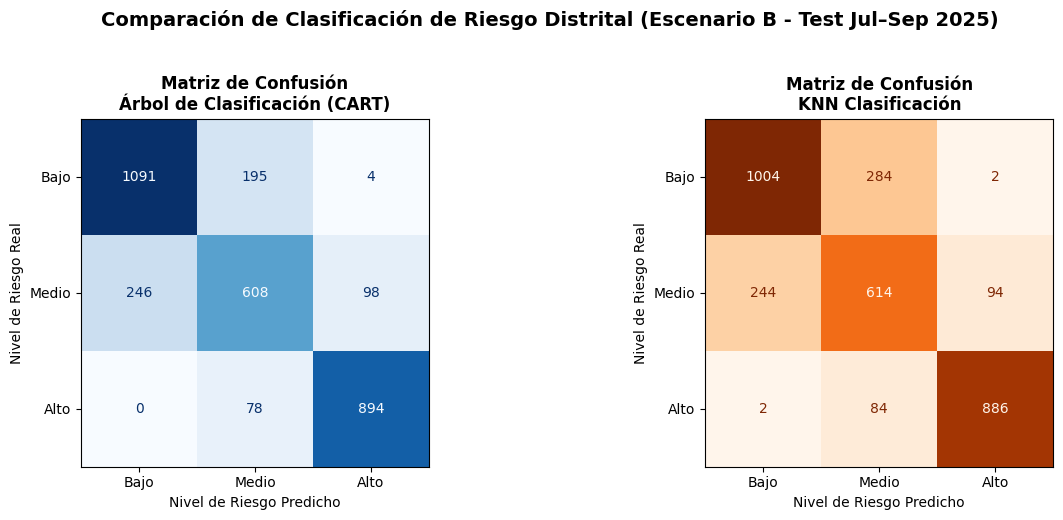

=== PRUEBA ESTADÍSTICA DE McNEMAR (ÁRBOL DE CLASIFICACIÓN VS. KNN) ===
Aciertos exclusivos Árbol: 275 | Aciertos exclusivos KNN: 186
Estadístico Chi-cuadrado: 16.7983
Valor p (p-value):        4.1571e-05
Conclusión: Existe una diferencia estadísticamente significativa entre ambos modelos (p < 0.05).


In [176]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from statsmodels.stats.contingency_tables import mcnemar

# 1. Matrices de confusión lado a lado: Árbol de Clasificación vs KNN (Escenario B)
clases_orden = ['Bajo', 'Medio', 'Alto']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

modelos_a_comparar = [
    ("Árbol de Clasificación (CART)", preds_clf_B["Árbol de Clasificación (CART)"], "Blues"),
    ("KNN Clasificación", preds_clf_B["KNN Clasificación"], "Oranges")
]

for ax, (titulo, y_pred, cmap) in zip(axes, modelos_a_comparar):
    cm = confusion_matrix(y_test_clf, y_pred, labels=clases_orden)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=clases_orden)
    disp.plot(ax=ax, cmap=cmap, colorbar=False, values_format='d')
    ax.set_title(f"Matriz de Confusión\n{titulo}", fontweight='bold', fontsize=12)
    ax.set_xlabel("Nivel de Riesgo Predicho")
    ax.set_ylabel("Nivel de Riesgo Real")

plt.suptitle("Comparación de Clasificación de Riesgo Distrital (Escenario B - Test Jul–Sep 2025)", fontsize=14, fontweight='bold', y=1.03)
plt.tight_layout()
plt.show()

# 2. Prueba estadística de McNemar (Árbol de Clasificación vs KNN)
acierto_arbol = (preds_clf_B["Árbol de Clasificación (CART)"] == y_test_clf.values)
acierto_knn = (preds_clf_B["KNN Clasificación"] == y_test_clf.values)

# Tabla de contingencia 2x2 de aciertos/errores
n_ambos_bien = np.sum(acierto_arbol & acierto_knn)
n_solo_arbol = np.sum(acierto_arbol & ~acierto_knn)
n_solo_knn = np.sum(~acierto_arbol & acierto_knn)
n_ambos_mal = np.sum(~acierto_arbol & ~acierto_knn)

tabla_mcnemar = [[n_ambos_bien, n_solo_arbol],
                 [n_solo_knn, n_ambos_mal]]

resultado_mcnemar = mcnemar(tabla_mcnemar, exact=False, correction=True)

print("=== PRUEBA ESTADÍSTICA DE McNEMAR (ÁRBOL DE CLASIFICACIÓN VS. KNN) ===")
print(f"Aciertos exclusivos Árbol: {n_solo_arbol} | Aciertos exclusivos KNN: {n_solo_knn}")
print(f"Estadístico Chi-cuadrado: {resultado_mcnemar.statistic:.4f}")
print(f"Valor p (p-value):        {resultado_mcnemar.pvalue:.4e}")
if resultado_mcnemar.pvalue < 0.05:
    print("Conclusión: Existe una diferencia estadísticamente significativa entre ambos modelos (p < 0.05).")
else:
    print("Conclusión: No hay diferencia estadísticamente significativa entre ambos modelos (p >= 0.05).")

## 6. Análisis de Resultados, Explicabilidad y Aplicabilidad Policial
Interpretación integral de hallazgos experimentales, desagregación territorial y vinculación con la gestión de seguridad ciudadana.

### 6.1. Tabla comparativa global y desglose territorial (Lima Metropolitana vs. Provincias)
Consolidación de métricas globales de regresión (`MAE`, `RMSE`, `R²`, `WAPE`) comparando ambos escenarios, junto con una evaluación estratificada entre los distritos de Lima Metropolitana y el resto del país para verificar la capacidad de generalización territorial.

In [177]:
# 1. Consolidación de tablas de regresión (Escenario A vs B)
df_comparativa_reg = pd.concat([df_res_reg_A, df_res_reg_B], ignore_index=True)
print("=== RESUMEN GLOBAL REGRESIÓN: ESCENARIO A VS. ESCENARIO B ===")
display(df_comparativa_reg.sort_values(["Escenario", "MAE"]))

# 2. Desglose territorial: Lima vs. Regiones (Escenario B)
# Usamos startswith('LIMA') para capturar tanto LIMA METROPOLITANA como LIMA PROVINCIAS
es_lima_test = test_df['DEPARTAMENTO'].astype(str).str.strip().str.upper().str.startswith('LIMA').values

desglose_filas = []
for zona, mascara in [("Lima", es_lima_test), ("Regiones (Sin Lima)", ~es_lima_test)]:
    y_zona = y_test_reg.values[mascara]
    for nombre_mod, preds in preds_reg_B.items():
        y_pred_zona = preds[mascara]
        desglose_filas.append({
            "Ámbito Territorial": zona,
            "Modelo (Escenario B)": nombre_mod,
            "Distritos-Mes (N)": len(y_zona),
            "MAE": round(mean_absolute_error(y_zona, y_pred_zona), 3),
            "RMSE": round(root_mean_squared_error(y_zona, y_pred_zona), 3),
            "R2": round(r2_score(y_zona, y_pred_zona), 4),
            "WAPE (%)": round(calcular_wape(y_zona, y_pred_zona), 2)
        })

df_desglose_territorial = pd.DataFrame(desglose_filas)
print("\n=== DESGLOSE TERRITORIAL DEL ERROR DE REGRESIÓN (LIMA VS. REGIONES) ===")
display(df_desglose_territorial)

=== RESUMEN GLOBAL REGRESIÓN: ESCENARIO A VS. ESCENARIO B ===


,Escenario,Modelo,MAE,RMSE,R2,WAPE (%)
1,Escenario A (Solo Historia),Regresión Lineal,6.427,16.034,0.9850,15.84
4,Escenario A (Solo Historia),MLP Regressor,6.612,17.191,0.9828,16.30
0,Escenario A (Solo Historia),Baseline (Persistencia Lag 1),6.854,17.073,0.9830,16.90
3,Escenario A (Solo Historia),KNN Regresión,7.057,18.434,0.9802,17.40
2,Escenario A (Solo Historia),Árbol de Regresión (CART),7.193,21.953,0.9719,17.73
6,Escenario B (Consolidado),Regresión Lineal,6.625,16.904,0.9834,16.33
9,Escenario B (Consolidado),MLP Regressor,6.716,18.531,0.9800,16.56
5,Escenario B (Consolidado),Baseline (Persistencia Lag 1),6.854,17.073,0.9830,16.90
7,Escenario B (Consolidado),Árbol de Regresión (CART),7.566,22.914,0.9694,18.65
8,Escenario B (Consolidado),KNN Regresión,9.353,38.761,0.9125,23.06



=== DESGLOSE TERRITORIAL DEL ERROR DE REGRESIÓN (LIMA VS. REGIONES) ===


,Ámbito Territorial,Modelo (Escenario B),Distritos-Mes (N),MAE,RMSE,R2,WAPE (%)
0,Lima,Baseline (Persistencia Lag 1),128,30.766,50.979,0.9819,7.97
1,Lima,Regresión Lineal,128,33.235,53.705,0.9799,8.61
2,Lima,Árbol de Regresión (CART),128,45.134,81.146,0.9541,11.69
3,Lima,KNN Regresión,128,66.599,167.999,0.8034,17.25
4,Lima,MLP Regressor,128,38.109,63.282,0.9721,9.87
5,Regiones (Sin Lima),Baseline (Persistencia Lag 1),3086,5.863,13.992,0.9711,22.35
6,Regiones (Sin Lima),Regresión Lineal,3086,5.521,13.340,0.9737,21.04
7,Regiones (Sin Lima),Árbol de Regresión (CART),3086,6.007,16.544,0.9596,22.90
8,Regiones (Sin Lima),KNN Regresión,3086,6.979,19.851,0.9418,26.60
9,Regiones (Sin Lima),MLP Regressor,3086,5.414,13.840,0.9717,20.64


### 6.2. Importancia de variables multisectoriales (Feature Importance)
Extracción y visualización de la relevancia relativa de las variables predictoras en los modelos basados en árboles de decisión (tanto en Regresión de conteo como en Clasificación de riesgo), cuantificando el aporte de las fuentes socioeconómicas, policiales y de infraestructura urbana.

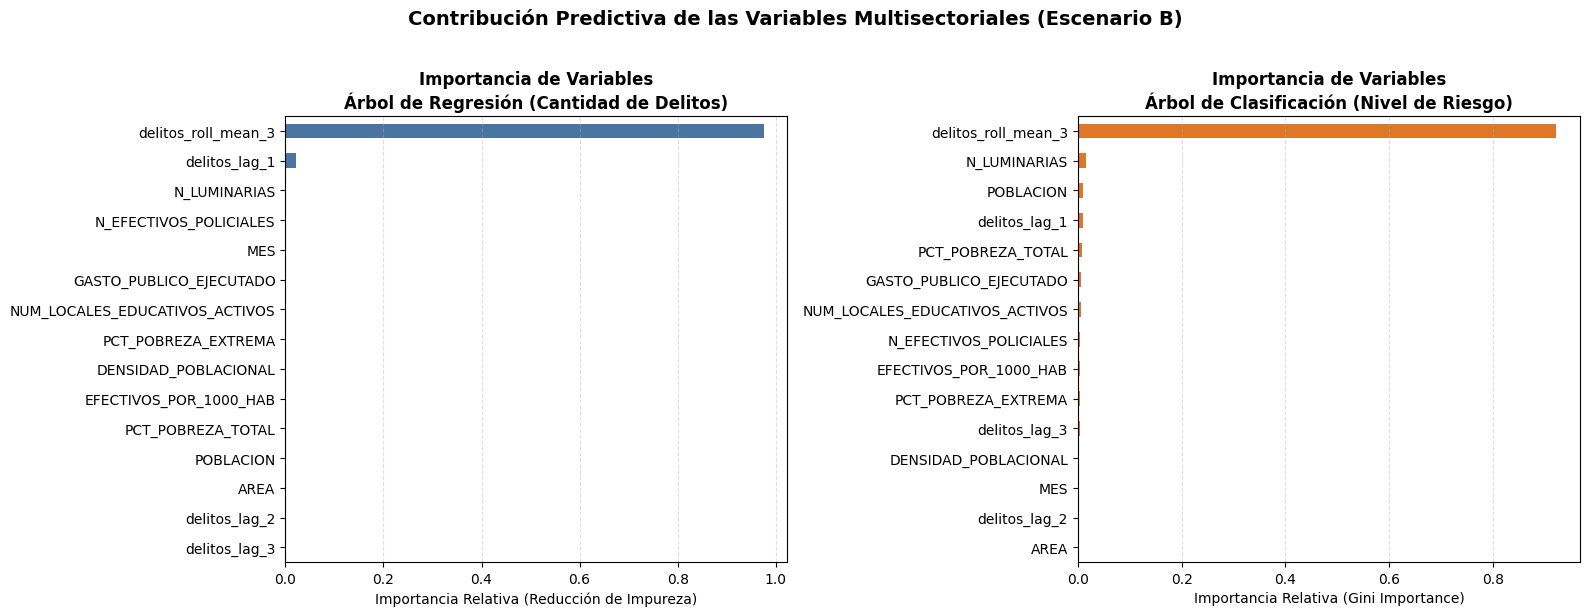

=== PESO RELATIVO DE LAS VARIABLES EXTERNAS (MULTISECTORIALES) ===


,Variable Multisectorial,Importancia Regresión (%),Importancia Clasificación (%)
8,N_LUMINARIAS,0.16,1.49
0,POBLACION,0.00,1.01
2,PCT_POBREZA_TOTAL,0.00,0.81
7,GASTO_PUBLICO_EJECUTADO,0.00,0.68
9,NUM_LOCALES_EDUCATIVOS_ACTIVOS,0.00,0.53
5,N_EFECTIVOS_POLICIALES,0.04,0.49
6,EFECTIVOS_POR_1000_HAB,0.00,0.48
3,PCT_POBREZA_EXTREMA,0.00,0.34
4,DENSIDAD_POBLACIONAL,0.00,0.28
1,AREA,0.00,0.03


In [178]:
# Extraer importancia de variables de ambos árboles entrenados en Escenario B
imp_reg = pd.Series(best_tree_reg.feature_importances_, index=features_escenario_B).sort_values(ascending=True)
arbol_clf_B = modelos_clf_B["Árbol de Clasificación (CART)"]
imp_clf = pd.Series(arbol_clf_B.feature_importances_, index=features_escenario_B).sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Gráfico 1: Importancia en Regresión (Cantidad de Delitos)
imp_reg.plot(kind='barh', ax=axes[0], color='#2B5C8F', alpha=0.85)
axes[0].set_title("Importancia de Variables\nÁrbol de Regresión (Cantidad de Delitos)", fontweight='bold', fontsize=12)
axes[0].set_xlabel("Importancia Relativa (Reducción de Impureza)")
axes[0].grid(axis='x', linestyle='--', alpha=0.4)

# Gráfico 2: Importancia en Clasificación (Nivel de Riesgo)
imp_clf.plot(kind='barh', ax=axes[1], color='#D95F02', alpha=0.85)
axes[1].set_title("Importancia de Variables\nÁrbol de Clasificación (Nivel de Riesgo)", fontweight='bold', fontsize=12)
axes[1].set_xlabel("Importancia Relativa (Gini Importance)")
axes[1].grid(axis='x', linestyle='--', alpha=0.4)

plt.suptitle("Contribución Predictiva de las Variables Multisectoriales (Escenario B)", fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Mostrar tabla numérica del peso exclusivamente de las 10 variables externas (excluyendo rezagos)
vars_externas = [
    'POBLACION', 'AREA', 'PCT_POBREZA_TOTAL', 'PCT_POBREZA_EXTREMA',
    'DENSIDAD_POBLACIONAL', 'N_EFECTIVOS_POLICIALES', 'EFECTIVOS_POR_1000_HAB',
    'GASTO_PUBLICO_EJECUTADO', 'N_LUMINARIAS', 'NUM_LOCALES_EDUCATIVOS_ACTIVOS'
]
df_peso_datasets = pd.DataFrame({
    "Variable Multisectorial": vars_externas,
    "Importancia Regresión (%)": (imp_reg[vars_externas] * 100).round(2).values,
    "Importancia Clasificación (%)": (imp_clf[vars_externas] * 100).round(2).values
}).sort_values("Importancia Clasificación (%)", ascending=False)

print("=== PESO RELATIVO DE LAS VARIABLES EXTERNAS (MULTISECTORIALES) ===")
display(df_peso_datasets)

### 6.3. Índice de sobrecarga delictiva por efectivo policial y exportación de resultados
Se cruza la incidencia delictiva predicha ($\widehat{DELITOS\_PREDICHOS}$) con la dotación policial distrital (`N_EFECTIVOS_POLICIALES`) y el nivel de riesgo clasificado en el último trimestre evaluado (julio – septiembre 2025), identificando los distritos con mayor brecha de atención operativa y exportando las tablas resumen para el informe final.

In [179]:
# Construir tabla aplicada de gestión policial sobre el periodo de prueba (Jul - Sep 2025)
df_gestion = test_df[['ANIO', 'MES', 'DEPARTAMENTO', 'PROVINCIA', 'DISTRITO', 'UBIGEO',
                      'N_DELITOS', 'N_EFECTIVOS_POLICIALES', 'EFECTIVOS_POR_1000_HAB',
                      'PCT_POBREZA_TOTAL', 'N_LUMINARIAS']].copy()

# Usar las predicciones del Árbol de Regresión Optimizado y Árbol de Clasificación
df_gestion['DELITOS_PREDICHOS'] = np.round(np.clip(best_tree_reg.predict(test_df[features_escenario_B]), 0, None), 1)
df_gestion['RIESGO_REAL'] = y_test_clf.values
df_gestion['RIESGO_PREDICHO'] = preds_clf_B["Árbol de Clasificación (CART)"]

# Ratio de carga delictiva estimada por cada efectivo policial asignado
df_gestion['DELITOS_PRED_POR_POLICIA'] = (
    df_gestion['DELITOS_PREDICHOS'] / df_gestion['N_EFECTIVOS_POLICIALES'].replace(0, np.nan)
).round(2)

# Resumen promedio mensual por distrito en el 4to trimestre 2025 (Top 15 distritos críticos)
top_distritos_criticos = (
    df_gestion.groupby(['DEPARTAMENTO', 'PROVINCIA', 'DISTRITO', 'UBIGEO'], as_index=False)
    .agg({
        'N_DELITOS': 'mean',
        'DELITOS_PREDICHOS': 'mean',
        'N_EFECTIVOS_POLICIALES': 'mean',
        'DELITOS_PRED_POR_POLICIA': 'mean',
        'RIESGO_PREDICHO': lambda x: x.mode()[0]
    })
    .round(2)
    .sort_values('DELITOS_PRED_POR_POLICIA', ascending=False)
    .head(15)
)

print("=== TOP 15 DISTRITOS CON MAYOR SOBRECARGA DELICTIVA PREDICHA POR EFECTIVO POLICIAL (Jul–Sep 2025) ===")
display(top_distritos_criticos)

# Exportar todas las tablas de resultados a un archivo Excel multipestaña para el informe
with pd.ExcelWriter('Resultados_Experimento_Grupo8.xlsx') as writer:
    df_comparativa_reg.to_excel(writer, sheet_name='Regresion_Global_A_vs_B', index=False)
    df_desglose_territorial.to_excel(writer, sheet_name='Desglose_Lima_vs_Prov', index=False)
    df_comparativa_clf.to_excel(writer, sheet_name='Clasificacion_KNN_vs_Arbol', index=False)
    df_peso_datasets.to_excel(writer, sheet_name='Importancia_Variables', index=False)
    top_distritos_criticos.to_excel(writer, sheet_name='Top15_Sobrecarga_Policial', index=False)

print("\nArchivo 'Resultados_Experimento_Grupo8.xlsx' generado exitosamente para el informe final.")

=== TOP 15 DISTRITOS CON MAYOR SOBRECARGA DELICTIVA PREDICHA POR EFECTIVO POLICIAL (Jul–Sep 2025) ===


,DEPARTAMENTO,PROVINCIA,DISTRITO,UBIGEO,N_DELITOS,DELITOS_PREDICHOS,N_EFECTIVOS_POLICIALES,DELITOS_PRED_POR_POLICIA,RIESGO_PREDICHO
136,ANCASH,SANTA,CHIMBOTE,021801,394.33,416.40,24.0,17.35,Alto
896,LIMA METROPOLITANA,LIMA,LURIGANCHO - CHOSICA,150118,372.33,366.00,24.0,15.25,Alto
607,HUANUCO,HUANUCO,HUANUCO,100101,202.67,207.00,24.0,8.62,Alto
604,HUANUCO,HUANUCO,AMARILIS,100102,153.00,203.63,24.0,8.49,Alto
710,JUNIN,HUANCAYO,EL TAMBO,120114,160.67,193.00,24.0,8.04,Alto
84,ANCASH,HUARAZ,HUARAZ,020101,184.33,193.00,24.0,8.04,Alto
155,APURIMAC,ABANCAY,ABANCAY,030101,165.00,193.00,24.0,8.04,Alto
1015,PIURA,PIURA,26 DE OCTUBRE,200115,189.67,183.20,24.0,7.63,Alto
623,HUANUCO,LEONCIO PRADO,RUPA-RUPA,100601,157.33,173.40,24.0,7.23,Alto
1255,SAN MARTIN,SAN MARTIN,TARAPOTO,220901,144.33,163.60,24.0,6.82,Alto



Archivo 'Resultados_Experimento_Grupo8.xlsx' generado exitosamente para el informe final.
